In [1]:
import importlib.util, importlib.metadata as md, subprocess, sys


def _version(dist):
    try:
        return md.version(dist)
    except md.PackageNotFoundError:
        return None


def _accepts_installed_numpy(dist):
    """Does `dist`'s declared NumPy requirement accept the NumPy installed here?"""
    try:
        from packaging.requirements import Requirement
        for r in md.requires(dist) or []:
            req = Requirement(r)
            if req.name.lower() == "numpy" and req.marker is None:
                return req.specifier.contains(md.version("numpy"), prereleases=True)
    except Exception:
        pass
    return True


pins = [f"{d}=={_version(d)}" for d in ("numpy", "scipy") if _version(d)]   # never upgrade these
need = [spec for module, spec in {"pylatexenc": "pylatexenc", "docx": "python-docx", "openpyxl": "openpyxl"}.items()
        if importlib.util.find_spec(module) is None]
if _version("qiskit") is not None and not _accepts_installed_numpy("qiskit"):
    print(f"Installed Qiskit {_version('qiskit')} needs a different NumPy than {_version('numpy')} -> replacing it")
    subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "qiskit"])
if _version("qiskit") is None:
    need.append("qiskit>=1.3,<3")
if need:
    print("Installing:", need, "| keeping:", pins)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need, *pins])

# The libraries must still import with the NumPy on disk (an earlier, unpinned install may have upgraded it)
probe = subprocess.run([sys.executable, "-c", "import numpy, scipy, pandas, sklearn, cv2, matplotlib, qiskit"],
                       capture_output=True, text=True)
if probe.returncode != 0:
    raise SystemExit("The Python environment is inconsistent (usually: NumPy was upgraded by an earlier pip install).\n"
                     "Kaggle: menu Run -> Factory reset, then Run All.\n\n" + probe.stderr[-1500:])
loaded = {m for m in ("numpy", "qiskit") if m in sys.modules}
print(f"numpy {_version('numpy')} | scipy {_version('scipy')} | qiskit {_version('qiskit')}")
if loaded:
    print(f"NOTE: {sorted(loaded)} already loaded in this kernel. If anything was installed above, restart the kernel "
          "(Run -> Restart & clear cell outputs) and Run All.")

Installing: ['pylatexenc', 'python-docx', 'qiskit>=1.3,<3'] | keeping: ['numpy==2.1.3', 'scipy==1.16.3']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.3 MB/s eta 0:00:00
numpy 2.1.3 | scipy 1.16.3 | qiskit 2.5.2
NOTE: ['numpy'] already loaded in this kernel. If anything was installed above, restart the kernel (Run -> Restart & clear cell outputs) and Run All.


In [2]:
import os

# ---- data -------------------------------------------------------------------------------------
DATA_ROOT = os.environ.get("QEXAI_DATA_ROOT", "/kaggle/input")
OUT_DIR = "/kaggle/working/qexai_outputs" if os.path.isdir("/kaggle/working") else os.path.abspath("qexai_outputs")
DATASET_NAME = ("the OASIS-1 cross-sectional MRI data (Marcus et al., 2007) in the 2D-slice version distributed on "
                "Kaggle as “OASIS Alzheimer's Detection”")
DATASET_CITATION = "[cite: Marcus et al., 2007; https://www.kaggle.com/datasets/ninadaithal/imagesoasis]"

# Labels follow the Clinical Dementia Rating (CDR) encoded in the folder names:
# Non Demented = 0, Very mild Dementia = 0.5, Mild Dementia = 1, Moderate Dementia = 2.
AD_MIN_CDR = 0.5          # AD = CDR >= 0.5: very mild to moderate AD, the OASIS-1 definition (100 subjects).
                          # Use 1.0 for mild + moderate only (30 subjects); CDR 0.5 subjects are then excluded.
CN_MIN_AGE = 60           # age-matching: keep CN subjects aged >= 60 (all OASIS-1 dementia cases are over 60). None = no filter
REQUIRE_DEMOGRAPHICS = True   # stop if the OASIS-1 demographics table cannot be found or downloaded
# Where the OASIS-1 demographics table comes from (first that works):
#  1) DEMOGRAPHICS_FILE: explicit path to oasis_cross-sectional.csv / .xlsx that you uploaded, e.g.
#     "/kaggle/input/oasis-demographics/oasis_cross-sectional.xlsx"
#  2) any matching .csv/.xlsx attached under DATA_ROOT (e.g. Kaggle dataset jboysen/mri-and-alzheimers)
#  3) download of the official OASIS-1 spreadsheet (Kaggle: Settings -> Internet ON)
DEMOGRAPHICS_FILE = None
DEMOGRAPHICS_URLS = [
    "https://bpb-us-e2.wpmucdn.com/sites.wustl.edu/dist/6/4383/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx",
    "https://sites.wustl.edu/oasisbrains/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx",
]
MAX_PER_CLASS = 900       # manuscript: ~900 images per class, spread evenly over the subjects of each class
SLICES_PER_SUBJECT = None # None = MAX_PER_CLASS / number of subjects; or a fixed number per subject
SLICE_RANGE = (100, 160)  # axial slice indices to sample from (the Kaggle set contains 100-160)

# ---- evaluation ----------------------------------------------------------------------------------
SEED = 42
N_FOLDS = 5          # stratified, group-level K-fold cross-validation (each image is tested exactly once)
VAL_FRAC = 0.15      # share of each training fold held out (by group) for early stopping / model selection
N_BOOTSTRAP = 1000   # group-level bootstrap resamples for 95% CIs

# ---- CNN (Sec. 3.3) -------------------------------------------------------------------------------
IMG_SIZE = 224
CNN_WIDTHS = (32, 64, 128, 256, 256)   # 5 conv blocks: 2 × (3×3 conv + BN + ReLU) + 2×2 max-pool
FEATURE_DIM = 4096
CNN_DROPOUT = 0.5
BATCH_SIZE = 16
CNN_LR = 1e-3
CNN_EPOCHS = 20
CNN_PATIENCE = 5

# ---- PCA + quantum part (Sec. 3.4–3.7) ------------------------------------------------------------------
N_PCA = 64
N_QUBITS = 4                 # leading PCA components encoded on N_QUBITS qubits (one component per qubit)
ENCODING = "zz"              # "zz" = ZZ feature map (Fig. 7) | "angle" = RY(x_i) angle encoding
FM_REPS = 2                  # feature-map repetitions (ZZ only)
ANSATZ_REPS = 2              # RealAmplitudes layers
ENTANGLEMENT = "linear"      # "linear" | "full"
Q_LR = 0.03
Q_EPOCHS = 80
Q_PATIENCE = 10
Q_BATCH = 32
Q_RESTARTS = 3               # random initialisations per quantum/linear head; the one with the lowest validation loss is kept

# ---- extra analyses -------------------------------------------------------------------------------
RUN_QUBIT_SWEEP = True
SWEEP_QUBITS = [4, 5, 6, 7, 8]
SHOTS_LIST = [128, 1024, 8192]
N_SHOT_SEEDS = 5
N_GRADCAM_EXAMPLES = 3       # per class in Figure 12

# ---- values printed in the 24-Jun-2026 manuscript (used ONLY in the verification report) ----------------
REPORTED = {"cnn":    dict(accuracy=97.0, precision=97.0, recall=97.0, f1=97.0, auc=0.98),
            "vqc":    dict(accuracy=95.0, precision=95.0, recall=94.0, f1=94.5, auc=0.96),
            "hybrid": dict(accuracy=96.0, precision=96.0, recall=95.0, f1=95.5, auc=0.97)}

# ---- smoke test (never report these numbers) ---------------------------------------------------------
FAST_DEV_RUN = os.environ.get("QEXAI_FAST_DEV_RUN", "0") == "1"
if FAST_DEV_RUN:
    IMG_SIZE, MAX_PER_CLASS, N_FOLDS, CNN_EPOCHS, Q_EPOCHS = 64, 120, 3, 3, 15
    SWEEP_QUBITS, SHOTS_LIST, N_SHOT_SEEDS, N_BOOTSTRAP = [4, 5], [128, 1024], 2, 100
    print("FAST_DEV_RUN = True — smoke test only. DO NOT use these outputs in the manuscript.")

In [3]:
import copy, json, math, os, re, sys, time, random, hashlib, platform, warnings, zipfile, datetime
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as IPImage
from scipy import stats
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

os.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")      # in case TensorFlow is imported later
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorSampler

warnings.filterwarnings("ignore", category=UserWarning)

# ---- environment checks (version mismatch, Qiskit/NumPy compatibility, free GPU memory) ----
import importlib.metadata as _md
if np.__version__ != _md.version("numpy"):
    raise SystemExit(f"This kernel runs NumPy {np.__version__}, but NumPy {_md.version('numpy')} is installed on disk. "
                     "Restart the kernel (Run -> Restart & clear cell outputs) and Run All; if it persists, Run -> Factory reset.")
try:
    _qc = QuantumCircuit(1); _qc.h(0); Statevector(_qc)
except Exception as e:
    raise SystemExit(f"Qiskit {qiskit.__version__} does not work with NumPy {np.__version__} ({e}). "
                     "Run -> Factory reset, then Run All (the installation cell pins compatible versions).")
if torch.cuda.is_available():
    free_b, total_b = torch.cuda.mem_get_info()
    print(f"GPU memory free: {free_b / 2**30:.1f} of {total_b / 2**30:.1f} GB")
    if free_b < 1.5 * 2**30:
        holders = [m for m in ("tensorflow", "keras", "jax") if m in sys.modules]
        raise SystemExit(
            f"Only {free_b / 2**20:.0f} MB of GPU memory is free: another library or an earlier run is holding it"
            + (f" (loaded here: {holders})" if holders else "") + ".\n"
            "Fix: Run -> Restart & clear cell outputs, then Run All. Run this notebook on its own — do not mix it with "
            "TensorFlow/Keras cells from another notebook in the same session.")
for sub in ("figures", "tables", "models"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Q_DEVICE = torch.device("cpu")   # the small quantum/linear heads train faster on CPU (no GPU kernel-launch overhead)
NUM_WORKERS = 2 if (os.cpu_count() or 1) > 2 else 0


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
ENV = {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
       "qiskit": qiskit.__version__, "scikit-learn": sklearn.__version__, "opencv": cv2.__version__,
       "numpy": np.__version__,
       "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else f"CPU ({os.cpu_count()} cores)"}
print(json.dumps(ENV, indent=1))

# Figure style — categorical slots from a colour-blind-validated palette (first three slots validate all-pairs)
COLORS = {"cnn": "#2a78d6", "vqc": "#eb6834", "hybrid": "#1baf7a", "lin_n": "#8a8984", "lin64": "#52514e"}
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
NAMES = {"cnn": "CNN", "vqc": "VQC", "hybrid": "Hybrid CNN–VQC",
         "lin_n": f"Linear on {N_QUBITS} PCA comps (classical ablation)",
         "lin64": f"Linear on {N_PCA} PCA comps (classical ablation)"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "legend.frameon": False, "figure.dpi": 100})


def savefig(fig, name):
    path = os.path.join(OUT_DIR, "figures", f"{name}.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    fig.savefig(path[:-4] + ".pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return path

GPU memory free: 14.5 of 14.6 GB
{
 "python": "3.13.15",
 "torch": "2.11.0+cu128",
 "torchvision": "0.26.0+cu128",
 "qiskit": "2.5.2",
 "scikit-learn": "1.6.1",
 "opencv": "4.14.0",
 "numpy": "2.1.3",
 "device": "Tesla T4"
}


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
_norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
CDR_BY_FOLDER = {"nondemented": 0.0, "verymilddementia": 0.5, "verymilddemented": 0.5, "milddementia": 1.0,
                 "milddemented": 1.0, "moderatedementia": 2.0, "moderatedemented": 2.0}
FNAME_RE = re.compile(r"(OAS1_\d{4})_(MR\d)_mpr-(\d+)_(\d+)", re.IGNORECASE)

rows, unparsed, csv_files = [], [], []
for root, dirs, files in os.walk(DATA_ROOT, followlinks=True):   # Kaggle may mount inputs as symlinks
    dirs.sort()
    for f in sorted(files):
        ext = Path(f).suffix.lower()
        if ext in (".csv", ".xlsx", ".xls"):
            csv_files.append(os.path.join(root, f))
            continue
        if ext not in IMG_EXT:
            continue
        folder = Path(root).name
        cdr = CDR_BY_FOLDER.get(_norm(folder))
        if cdr is None:
            continue
        m = FNAME_RE.search(f)
        if m is None:
            unparsed.append(os.path.join(root, f))
            continue
        p = os.path.join(root, f)
        rows.append(dict(path=p, rel=os.path.relpath(p, DATA_ROOT), folder=folder, cdr_folder=cdr,
                         subject=m.group(1).upper(), session=m.group(2).upper(), mpr=int(m.group(3)), slice=int(m.group(4))))
df_all = pd.DataFrame(rows)
if df_all.empty:
    raise SystemExit(f"No OASIS images found under {DATA_ROOT}. Attach 'ninadaithal/imagesoasis' with 'Add Data'.")
if unparsed:
    print(f"{len(unparsed)} images in class folders do not follow the OASIS filename pattern and were skipped, e.g.:",
          *unparsed[:3], sep="\n  ")
n_raw = len(df_all)
df_all = df_all.drop_duplicates(["subject", "session", "mpr", "slice"]).reset_index(drop=True)   # dataset attached twice etc.
print(f"Images found: {n_raw:,} ({n_raw - len(df_all):,} duplicate copies removed)")
INVENTORY = (df_all.assign(scan=df_all.subject + df_all.session + df_all.mpr.astype(str))
             .groupby(["folder", "cdr_folder"])
             .agg(images=("path", "size"), subjects=("subject", "nunique"), scans=("scan", "nunique"),
                  first_slice=("slice", "min"), last_slice=("slice", "max")).reset_index().sort_values("cdr_folder"))
display(INVENTORY)
INVENTORY.to_csv(os.path.join(OUT_DIR, "tables", "data_inventory.csv"), index=False)
_probe = cv2.imread(df_all.path.iloc[0], cv2.IMREAD_UNCHANGED)
print("Example file:", df_all.rel.iloc[0], "| stored size (H, W[, C]):", None if _probe is None else _probe.shape)

# a subject must sit in exactly one CDR folder
n_folders = df_all.groupby("subject").folder.nunique()
if (n_folders > 1).any():
    bad = n_folders[n_folders > 1].index
    print(f"Dropping {len(bad)} subjects that appear in more than one CDR folder:", list(bad)[:10])
    df_all = df_all[~df_all.subject.isin(bad)].reset_index(drop=True)

# ---- OASIS-1 demographics (oasis_cross-sectional.csv / .xlsx) ----
def read_oasis_demographics(path, log=None):
    """Return the OASIS-1 table indexed by subject (MR1 rows), or None if the file is not that table."""
    log = log if log is not None else []
    try:
        if str(path).lower().endswith((".xlsx", ".xls")):
            raw = pd.read_excel(path, header=None)
            hdr = next((i for i in range(min(15, len(raw))) if "ID" in [str(v).strip() for v in raw.iloc[i]]), None)
            if hdr is None:
                log.append(f"{path}: no 'ID' header row"); return None
            d = pd.read_excel(path, header=hdr)
        else:
            d = pd.read_csv(path, encoding="utf-8-sig", sep=None, engine="python")
    except Exception as e:
        log.append(f"{path}: could not be read ({type(e).__name__}: {e})"); return None
    d.columns = [str(c).replace("\ufeff", "").strip() for c in d.columns]
    if not {"ID", "Age", "CDR"} <= set(d.columns):
        log.append(f"{path}: columns {list(d.columns)[:8]} (needs ID, Age, CDR)"); return None
    ids = d.ID.astype(str).str.strip().str.upper()
    if not ids.str.startswith("OAS1_").any():
        log.append(f"{path}: IDs are not OASIS-1 (e.g. {ids.iloc[0] if len(ids) else 'empty'})"); return None
    d = d[ids.str.endswith("_MR1")].copy()
    d["subject"] = d.ID.astype(str).str.strip().str[:9].str.upper()
    for c in ("Age", "MMSE", "CDR", "Educ", "SES", "eTIV", "nWBV"):
        if c in d:
            d[c] = pd.to_numeric(d[c], errors="coerce")
    if "M/F" in d:
        d["M/F"] = d["M/F"].astype(str).str.strip().str.upper()
    return d.drop_duplicates("subject").set_index("subject")


def download(url, dst):
    """Browser-like download; returns (ok, message). Accepts only an Excel (zip) or CSV payload."""
    headers = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124 Safari/537.36",
               "Accept": "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet,text/csv,*/*"}
    try:
        try:
            import requests
            r = requests.get(url, headers=headers, timeout=60, allow_redirects=True)
            status, data = r.status_code, r.content
        except ImportError:
            import urllib.request
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=60) as r:
                status, data = r.status, r.read()
    except Exception as e:
        return False, f"{type(e).__name__}: {str(e)[:160]}"
    if status != 200:
        return False, f"HTTP {status}"
    if not (data[:2] == b"PK" or data[:3] == b"ID," or data[:6] == b"\xef\xbb\xbfID,"):
        return False, f"unexpected content ({len(data)} bytes, starts {data[:40]!r})"
    with open(dst, "wb") as fh:
        fh.write(data)
    return True, f"{len(data):,} bytes"


DEMO, DEMO_PATH, demo_log = None, None, []
candidates = ([DEMOGRAPHICS_FILE] if DEMOGRAPHICS_FILE else []) + sorted(csv_files)
for cp in candidates:                               # 1) + 2) files you attached / uploaded
    DEMO = read_oasis_demographics(cp, demo_log)
    if DEMO is not None:
        DEMO_PATH = cp
        break
if DEMO is None:                                    # 3) official OASIS-1 spreadsheet (Internet ON)
    for url in DEMOGRAPHICS_URLS or []:
        dst = os.path.join(OUT_DIR, "oasis_cross-sectional" + (".xlsx" if url.lower().endswith(".xlsx") else ".csv"))
        ok_dl, msg = download(url, dst)
        demo_log.append(f"download {url[:70]}... -> {msg}")
        if ok_dl:
            DEMO = read_oasis_demographics(dst, demo_log)
            if DEMO is not None:
                DEMO_PATH = url + " (downloaded)"
                break
if DEMO is None:
    print("Demographics search log:", *(demo_log or ["no .csv/.xlsx files under DATA_ROOT and no download URL"]), sep="\n  ")
if DEMO is None and REQUIRE_DEMOGRAPHICS:
    raise SystemExit(
        "OASIS-1 demographics (age/sex/MMSE/CDR) not found — see the search log printed above. Fix with ONE of these:\n"
        "  (a) Kaggle: right panel -> '+ Add Input' -> Datasets -> search 'MRI and Alzheimers' (owner: jboysen) -> Add;\n"
        "  (b) download https://sites.wustl.edu/oasisbrains/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx\n"
        "      in your browser, then Kaggle: '+ Add Input' -> 'Upload' -> New dataset -> drop the .xlsx -> Create,\n"
        "      and set DEMOGRAPHICS_FILE to its path (shown under Input in the right panel), or leave it None;\n"
        "  (c) last resort: set REQUIRE_DEMOGRAPHICS = False (controls then include adults aged 18-59: age confound).\n"
        "Then re-run the Configuration cell and this cell.")
print("Demographics:", DEMO_PATH or "NOT AVAILABLE — controls cannot be age-matched",
      "" if DEMO is None else f"({len(DEMO)} OASIS-1 subjects)")

SUBJ_TAB = df_all.groupby("subject").agg(folder=("folder", "first"), cdr=("cdr_folder", "first")).reset_index()
if DEMO is not None:
    keep_cols = [c for c in ("M/F", "Age", "Educ", "SES", "MMSE", "CDR", "eTIV", "nWBV") if c in DEMO.columns]
    SUBJ_TAB = SUBJ_TAB.join(DEMO[keep_cols], on="subject")
    mism = SUBJ_TAB[SUBJ_TAB.CDR.notna() & (SUBJ_TAB.CDR != SUBJ_TAB.cdr)]
    if len(mism):
        print(f"Dropping {len(mism)} subjects whose folder CDR differs from the CSV CDR:", list(mism.subject)[:10])
        SUBJ_TAB = SUBJ_TAB.drop(mism.index)
    print(f"Subjects with demographics: {int(SUBJ_TAB.Age.notna().sum())} of {len(SUBJ_TAB)}")
SUBJ_TAB["label"] = np.where(SUBJ_TAB.cdr >= AD_MIN_CDR, 1, np.where(SUBJ_TAB.cdr == 0, 0, -1))
SUBJ_TAB["reason"] = np.where(SUBJ_TAB.label == -1, f"CDR between 0 and {AD_MIN_CDR:g}", "")
AGE_MATCHED = DEMO is not None and CN_MIN_AGE is not None
if AGE_MATCHED:
    young = (SUBJ_TAB.label == 0) & ~(SUBJ_TAB.Age >= CN_MIN_AGE)
    SUBJ_TAB.loc[young, ["label", "reason"]] = [-1, f"CN younger than {CN_MIN_AGE} (or age missing)"]
else:
    print("WARNING: controls are NOT age-matched; the generated text states this as a limitation.")
display(SUBJ_TAB.assign(group=SUBJ_TAB.label.map({0: "CN", 1: "AD", -1: "excluded"}))
        .groupby(["folder", "group", "reason"]).size().rename("subjects").reset_index())

# ---- slice selection: one session + one acquisition per subject, evenly spaced slices ----
rng = np.random.default_rng(SEED)
pick = []
for lab in (0, 1):
    subs = SUBJ_TAB.loc[SUBJ_TAB.label == lab, "subject"].values
    scans = {}
    for sbj in subs:
        g = df_all[df_all.subject == sbj]
        ses = "MR1" if (g.session == "MR1").any() else sorted(g.session.unique())[0]
        g = g[g.session == ses]
        g = g[(g.mpr == g.mpr.min()) & g.slice.between(*SLICE_RANGE)].sort_values("slice")
        scans[sbj] = g
    avail = sum(len(v) for v in scans.values())
    target = min(MAX_PER_CLASS or avail, avail)
    if SLICES_PER_SUBJECT:
        quota = {sbj: SLICES_PER_SUBJECT for sbj in subs}
    else:
        base, extra = divmod(target, len(subs))
        lucky = set(rng.choice(subs, extra, replace=False)) if extra else set()
        quota = {sbj: base + (sbj in lucky) for sbj in subs}
    for sbj, g in scans.items():
        k = min(quota[sbj], len(g))
        if k:
            pick.append(g.iloc[np.unique(np.round(np.linspace(0, len(g) - 1, k)).astype(int))])
df = pd.concat(pick).reset_index(drop=True)
df["label"] = df.subject.map(SUBJ_TAB.set_index("subject").label).astype(int)
while (df.label == 0).sum() != (df.label == 1).sum():          # exact class balance: trim the larger class
    big = int((df.label == 1).sum() > (df.label == 0).sum())
    counts = df[df.label == big].subject.value_counts()
    df = df.drop(df[(df.subject == counts.index[0])].index[-1])
df = df.reset_index(drop=True)
print(f"Selected {len(df)} images: CN {int((df.label == 0).sum())} from {df[df.label == 0].subject.nunique()} subjects, "
      f"AD {int((df.label == 1).sum())} from {df[df.label == 1].subject.nunique()} subjects; "
      f"slices per subject {df.groupby('subject').size().min()}–{df.groupby('subject').size().max()}")

Images found: 86,437 (0 duplicate copies removed)


,folder,cdr_folder,images,subjects,scans,first_slice,last_slice
2,Non Demented,0.0,67222,266,1102,100,160
3,Very mild Dementia,0.5,13725,58,225,100,160
0,Mild Dementia,1.0,5002,21,82,100,160
1,Moderate Dementia,2.0,488,2,8,100,160


Example file: datasets/ninadaithal/imagesoasis/Data/Mild Dementia/OAS1_0028_MR1_mpr-1_100.jpg | stored size (H, W[, C]): (248, 496, 3)
Demographics: https://bpb-us-e2.wpmucdn.com/sites.wustl.edu/dist/6/4383/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx (downloaded) (416 OASIS-1 subjects)
Subjects with demographics: 347 of 347


,folder,group,reason,subjects
0,Mild Dementia,AD,,21
1,Moderate Dementia,AD,,2
2,Non Demented,CN,,85
3,Non Demented,excluded,CN younger than 60 (or age missing),181
4,Very mild Dementia,AD,,58


Selected 1800 images: CN 900 from 85 subjects, AD 900 from 81 subjects; slices per subject 10–12


In [5]:
# ---- groups for splitting: subject, merged only if two subjects share a pixel-identical image (copied file) ----
# (A perceptual hash is NOT used: atlas-registered slices at the same position look alike across different people.)
hashes, ok = [], []
for p in df.path:
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    ok.append(im is not None and im.size > 0)
    hashes.append(hashlib.md5(im.tobytes()).hexdigest() if ok[-1] else None)
df["dhash"] = hashes
print("Unreadable files skipped:", int((~np.array(ok)).sum()))
df = df[np.array(ok)].reset_index(drop=True)
parent = {}
def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
for i, r in df.iterrows():
    union(f"subj:{r.subject}", f"hash:{r.dhash}")
df["group"] = pd.factorize(pd.Series([find(f"subj:{s_}") for s_ in df.subject]))[0]
merged = df.subject.nunique() - df.group.nunique()
print(f"Groups: {df.group.nunique()} ({merged} subjects merged because they shared a pixel-identical image)")
HAS_SUBJECT_IDS, GROUP_UNIT = True, "subject"

# ---- Table 1: demographics of the selected subjects ----
def _msd(v, nd=1):
    v = pd.to_numeric(v, errors="coerce").dropna()
    return f"{v.mean():.{nd}f} ± {v.std(ddof=1):.{nd}f}" if len(v) else "n/a"


sel_subj = SUBJ_TAB[SUBJ_TAB.subject.isin(df.subject.unique())].set_index("subject")
rows1 = []
for name, lab in (("CN", 0), ("AD", 1)):
    t = sel_subj[sel_subj.label == lab]
    r = dict(Group=name, Subjects=len(t), Images=int((df.label == lab).sum()),
             CDR=", ".join(f"{c:g}: {n}" for c, n in t.cdr.value_counts().sort_index().items()))
    if DEMO is not None:
        r.update({"Age (years)": f"{_msd(t.Age)} ({int(t.Age.min())}–{int(t.Age.max())})",
                  "Sex (F/M)": f"{int((t['M/F'] == 'F').sum())}/{int((t['M/F'] == 'M').sum())}" if "M/F" in t else "n/a",
                  "MMSE": _msd(t.MMSE) if "MMSE" in t else "n/a"})
    rows1.append(r)
TABLE1 = pd.DataFrame(rows1)
DEMO_TESTS = {}
if DEMO is not None:
    cn_s, ad_s = sel_subj[sel_subj.label == 0], sel_subj[sel_subj.label == 1]
    DEMO_TESTS["age_p"] = float(stats.ttest_ind(cn_s.Age.dropna(), ad_s.Age.dropna(), equal_var=False).pvalue)
    DEMO_TESTS.update(age_cn=_msd(cn_s.Age), age_ad=_msd(ad_s.Age),
                      mmse_cn=_msd(cn_s.MMSE) if "MMSE" in sel_subj else "n/a", mmse_ad=_msd(ad_s.MMSE) if "MMSE" in sel_subj else "n/a")
    if "M/F" in sel_subj:
        DEMO_TESTS["sex_p"] = float(stats.chi2_contingency(pd.crosstab(sel_subj.label, sel_subj["M/F"]))[1])
    if "MMSE" in sel_subj:
        DEMO_TESTS["mmse_p"] = float(stats.ttest_ind(cn_s.MMSE.dropna(), ad_s.MMSE.dropna(), equal_var=False).pvalue)
    TABLE1 = pd.concat([TABLE1, pd.DataFrame([dict(Group="p (CN vs AD)", Subjects="", Images="", CDR="",
                         **{"Age (years)": f"{DEMO_TESTS['age_p']:.3f}", "Sex (F/M)": f"{DEMO_TESTS.get('sex_p', np.nan):.3f}",
                            "MMSE": f"{DEMO_TESTS.get('mmse_p', np.nan):.3g}"})])], ignore_index=True)
TABLE1.to_csv(os.path.join(OUT_DIR, "tables", "table1_demographics.csv"), index=False)
display(TABLE1)

Unreadable files skipped: 0
Groups: 166 (0 subjects merged because they shared a pixel-identical image)


,Group,Subjects,Images,CDR,Age (years),Sex (F/M),MMSE
0,CN,85,900,0: 85,76.4 ± 8.9 (60–94),62/23,29.0 ± 1.2
1,AD,81,900,"0.5: 58, 1: 21, 2: 2",76.7 ± 7.3 (62–96),50/31,24.1 ± 4.3
2,p (CN vs AD),,,,0.794,0.169,5.92e-16


Image tensor: (1800, 224, 224) uint8


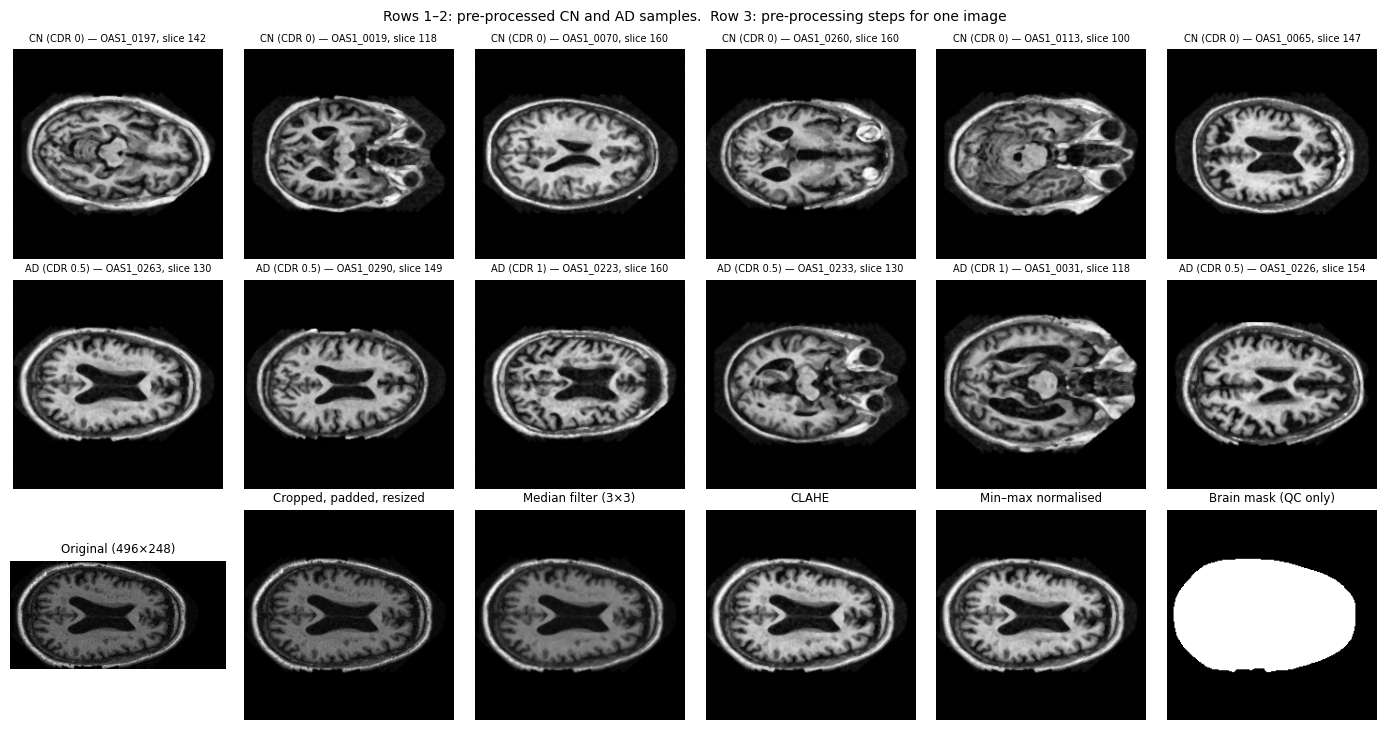

In [6]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def crop_pad_square(gray, thr=12, margin=0.04):
    """Crop to the content bounding box (relative to the border/background value), then pad to a square."""
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    bg = int(np.median(border))
    ys, xs = np.where(np.abs(gray.astype(np.int16) - bg) > thr)
    if len(ys) > 50:
        y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
        my, mx = int((y1 - y0) * margin) + 2, int((x1 - x0) * margin) + 2
        gray = gray[max(0, y0 - my):y1 + my + 1, max(0, x0 - mx):x1 + mx + 1]
    h, w = gray.shape
    side = max(h, w)
    out = np.full((side, side), bg, np.uint8)
    out[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = gray
    return out


def preprocess_steps(gray):
    r = cv2.resize(crop_pad_square(gray), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    d = cv2.medianBlur(r, 3)
    c = CLAHE.apply(d)
    n = cv2.normalize(c, None, 0, 255, cv2.NORM_MINMAX)
    return r, d, c, n


def brain_mask(img):
    _, m = cv2.threshold(cv2.GaussianBlur(img, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    n_lab, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n_lab > 1:
        m = np.where(lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA]), 255, 0).astype(np.uint8)
    # fill holes: background components that do not touch the image border belong to the brain (e.g. ventricles)
    n_bg, bg_lab = cv2.connectedComponents((m == 0).astype(np.uint8))
    border = np.unique(np.concatenate([bg_lab[0], bg_lab[-1], bg_lab[:, 0], bg_lab[:, -1]]))
    return (m > 0) | ((m == 0) & ~np.isin(bg_lab, border))


X = np.zeros((len(df), IMG_SIZE, IMG_SIZE), np.uint8)
for i, p in enumerate(df.path):
    X[i] = preprocess_steps(cv2.imread(p, cv2.IMREAD_GRAYSCALE))[-1]
y = df.label.values.astype(np.int64)
groups = df.group.values
print("Image tensor:", X.shape, X.dtype)

# Figure 1 / Figure 4: samples and the pre-processing pipeline
fig, axes = plt.subplots(3, 6, figsize=(14, 7.4))
for row, lab in enumerate((0, 1)):
    picks = rng.choice(np.where(y == lab)[0], 6, replace=False)
    for ax, i in zip(axes[row], picks):
        ax.imshow(X[i], cmap="gray"); ax.axis("off")
        ax.set_title(f"{'CN' if lab == 0 else 'AD'} (CDR {df.cdr_folder[i]:g}) — {df.subject[i]}, slice {df.slice[i]}", fontsize=7)
raw = cv2.imread(df.path[picks[0]], cv2.IMREAD_GRAYSCALE)
steps = preprocess_steps(raw)
titles = [f"Original ({raw.shape[1]}×{raw.shape[0]})", "Cropped, padded, resized", "Median filter (3×3)", "CLAHE",
          "Min–max normalised", "Brain mask (QC only)"]
for ax, im, t in zip(axes[2], [raw] + list(steps) + [brain_mask(steps[-1])], titles):
    ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=8.5); ax.axis("off")
fig.suptitle("Rows 1–2: pre-processed CN and AD samples.  Row 3: pre-processing steps for one image", fontsize=10)
fig.tight_layout()
FIGS = {"fig01": savefig(fig, "fig01_samples_and_preprocessing")}

In [7]:
outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS, split_rows = [], []
for k, (tr_all, te) in enumerate(outer.split(np.zeros(len(y)), y, groups)):
    inner = StratifiedGroupKFold(n_splits=max(2, round(1 / VAL_FRAC)), shuffle=True, random_state=SEED + k)
    fit_rel, val_rel = next(inner.split(np.zeros(len(tr_all)), y[tr_all], groups[tr_all]))
    tr, va = tr_all[fit_rel], tr_all[val_rel]
    g_tr, g_va, g_te = set(groups[tr]), set(groups[va]), set(groups[te])
    assert not (g_tr & g_te) and not (g_va & g_te) and not (g_tr & g_va), "group leakage between splits"
    FOLDS.append(dict(train=tr, val=va, test=te))
    split_rows.append(dict(fold=k, train_images=len(tr), val_images=len(va), test_images=len(te),
                           train_groups=len(g_tr), val_groups=len(g_va), test_groups=len(g_te),
                           test_AD_fraction=round(float(y[te].mean()), 3), groups_shared_with_test=0))
SPLITS = pd.DataFrame(split_rows)
SPLITS.to_csv(os.path.join(OUT_DIR, "tables", "cv_splits.csv"), index=False)
display(SPLITS)
assert sorted(np.concatenate([f["test"] for f in FOLDS]).tolist()) == list(range(len(y))), "each image must be tested once"
print("Leakage check PASSED: no group is shared between training, validation and test data in any fold.")

print("Test subjects per fold (CN / AD):",
      [f"{df.subject[f['test']][y[f['test']] == 0].nunique()} / {df.subject[f['test']][y[f['test']] == 1].nunique()}" for f in FOLDS])

,fold,train_images,val_images,test_images,train_groups,val_groups,test_groups,test_AD_fraction,groups_shared_with_test
0,0,1238,204,358,114,19,33,0.466,0
1,1,1248,192,360,115,18,33,0.467,0
2,2,1237,204,359,114,19,33,0.526,0
3,3,1239,204,357,114,19,33,0.524,0
4,4,1227,207,366,113,19,34,0.516,0


Leakage check PASSED: no group is shared between training, validation and test data in any fold.
Test subjects per fold (CN / AD): ['18 / 15', '18 / 15', '16 / 17', '16 / 17', '17 / 17']


In [8]:
class ADCNN(nn.Module):
    def __init__(self, widths=CNN_WIDTHS, feat_dim=FEATURE_DIM, dropout=CNN_DROPOUT):
        super().__init__()
        layers, c = [], 1
        for w in widths:
            layers += [nn.Conv2d(c, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(), nn.MaxPool2d(2)]
            c = w
        self.body = nn.Sequential(*layers[:-1])   # up to the last conv block (Grad-CAM target layer)
        self.last_pool = layers[-1]
        self.gap = nn.AdaptiveAvgPool2d(2)
        self.fc1 = nn.Linear(c * 4, feat_dim)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(feat_dim, 2)

    def embed_from_maps(self, A):
        return F.relu(self.fc1(torch.flatten(self.gap(self.last_pool(A)), 1)))

    def embed(self, x):
        return self.embed_from_maps(self.body(x))

    def forward(self, x):
        return self.fc2(self.drop(self.embed(x)))


AUG = T.Compose([T.RandomHorizontalFlip(), T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05))])


class MRIDataset(Dataset):
    def __init__(self, idx, augment):
        self.idx, self.augment = np.asarray(idx), augment

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = torch.from_numpy(X[j]).float().div(255).unsqueeze(0)
        if self.augment:
            img = AUG(img)
        return (img - 0.5) / 0.5, int(y[j])


def to_batch(idx):
    return ((torch.from_numpy(X[idx]).float().div(255).unsqueeze(1) - 0.5) / 0.5).to(DEVICE)


@torch.no_grad()
def cnn_predict(model, idx, bs=64):
    model.eval()
    probs, feats, losses = [], [], []
    for s in range(0, len(idx), bs):
        b = idx[s:s + bs]
        xb = to_batch(b)
        f = model.embed(xb)
        logits = model.fc2(f)
        losses.append(F.cross_entropy(logits, torch.from_numpy(y[b]).to(DEVICE), reduction="sum").item())
        probs.append(torch.softmax(logits, 1)[:, 1].cpu().numpy())
        feats.append(f.cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats).astype(np.float32), sum(losses) / len(idx)


def train_cnn(fold, seed):
    set_seed(seed)
    model = ADCNN().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CNN_LR)
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(MRIDataset(fold["train"], True), batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=NUM_WORKERS, generator=g)
    best, best_state, wait, hist = float("inf"), None, 0, []
    t0 = time.time()
    for ep in range(CNN_EPOCHS):
        model.train()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            loss.backward(); opt.step()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        pv, _, vl = cnn_predict(model, fold["val"])
        va = float(((pv >= 0.5) == y[fold["val"]]).mean())
        hist.append(dict(epoch=ep + 1, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=va))
        print(f"  epoch {ep + 1:2d}  train loss {tl / tn:.4f} acc {tc / tn:.3f} | val loss {vl:.4f} acc {va:.3f}")
        if vl < best - 1e-4:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CNN_PATIENCE:
                print(f"  early stopping at epoch {ep + 1}")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), time.time() - t0


_tmp = ADCNN()
N_PARAMS = {"cnn_total": sum(p.numel() for p in _tmp.parameters()),
            "cnn_conv": sum(p.numel() for p in _tmp.body.parameters()),
            "cnn_classification_part": sum(p.numel() for m in (_tmp.fc1, _tmp.fc2) for p in m.parameters())}
with torch.no_grad():
    _a = _tmp.body(torch.zeros(1, 1, IMG_SIZE, IMG_SIZE))
GRADCAM_MAP_SIZE = tuple(_a.shape[-2:])
print(_tmp)
print(N_PARAMS, "| Grad-CAM target maps:", tuple(_a.shape[1:]))
del _tmp, _a

ADCNN(
  (body): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel

In [9]:
def entangling_pairs(n, kind=ENTANGLEMENT):
    if kind == "linear":
        return [(i, i + 1) for i in range(n - 1)]
    if kind == "full":
        return [(i, j) for i in range(n) for j in range(i + 1, n)]
    raise ValueError("ENTANGLEMENT must be 'linear' or 'full'")


def qiskit_circuit(n):
    """Feature map + ansatz exactly as used in the paper (Figure 7)."""
    if ENCODING == "zz":
        fm = zz_feature_map(n, reps=FM_REPS, entanglement=ENTANGLEMENT)
    else:
        xv = ParameterVector("x", n)
        fm = QuantumCircuit(n, name="AngleEncoding")
        for i in range(n):
            fm.ry(xv[i], i)
    an = real_amplitudes(n, reps=ANSATZ_REPS, entanglement=ENTANGLEMENT)
    return fm.compose(an), list(fm.parameters), list(an.parameters)


_H = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex64) / math.sqrt(2)


def _apply_1q(psi, U, k):
    psi = psi.movedim(k + 1, -1)
    if U.dim() == 2:
        psi = psi @ U.transpose(0, 1)
    else:
        shp = psi.shape
        psi = torch.einsum("bmj,bij->bmi", psi.reshape(shp[0], -1, 2), U).reshape(shp)
    return psi.movedim(-1, k + 1)


def _apply_phase(psi, lam, k):          # P(lam) = diag(1, e^{i lam}); lam has shape (B,)
    psi = psi.movedim(k + 1, -1)
    ph = torch.exp(1j * lam).reshape((-1,) + (1,) * (psi.dim() - 2))
    psi = torch.stack((psi[..., 0], psi[..., 1] * ph), dim=-1)
    return psi.movedim(-1, k + 1)


def _apply_cx(psi, c, t):
    psi = torch.movedim(psi, (c + 1, t + 1), (-2, -1))
    psi = torch.stack((psi[..., 0, :], psi[..., 1, :].flip(-1)), dim=-2)
    return torch.movedim(psi, (-2, -1), (c + 1, t + 1))


def _ry(theta):                          # theta scalar -> (2,2) or (B,) -> (B,2,2)
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    U = torch.stack((torch.stack((c, -s), -1), torch.stack((s, c), -1)), -2)
    return torch.complex(U, torch.zeros_like(U))


class TorchVQC(nn.Module):
    """Exact state-vector simulation of qiskit_circuit(n); returns <Z_k> for every qubit k."""

    def __init__(self, n):
        super().__init__()
        self.n, self.pairs = n, entangling_pairs(n)
        self.theta = nn.Parameter(torch.empty(n * (ANSATZ_REPS + 1)).uniform_(-math.pi, math.pi))

    def forward(self, x):
        B, n = x.shape[0], self.n
        psi = torch.zeros((B, 2 ** n), dtype=torch.complex64, device=x.device)
        psi[:, 0] = 1
        psi = psi.reshape((B,) + (2,) * n)
        H = _H.to(x.device)
        if ENCODING == "zz":
            for _ in range(FM_REPS):
                for i in range(n):
                    psi = _apply_1q(psi, H, i)
                for i in range(n):
                    psi = _apply_phase(psi, 2 * x[:, i], i)
                for i, j in self.pairs:
                    psi = _apply_cx(psi, i, j)
                    psi = _apply_phase(psi, 2 * (math.pi - x[:, i]) * (math.pi - x[:, j]), j)
                    psi = _apply_cx(psi, i, j)
        else:
            for i in range(n):
                psi = _apply_1q(psi, _ry(x[:, i]), i)
        t = 0
        for _ in range(ANSATZ_REPS):
            for i in range(n):
                psi = _apply_1q(psi, _ry(self.theta[t]), i); t += 1
            for i, j in self.pairs:
                psi = _apply_cx(psi, i, j)
        for i in range(n):
            psi = _apply_1q(psi, _ry(self.theta[t]), i); t += 1
        prob = psi.real ** 2 + psi.imag ** 2
        out = []
        for k in range(n):
            pk = prob.movedim(k + 1, 1).reshape(B, 2, -1).sum(-1)
            out.append(pk[:, 0] - pk[:, 1])
        return torch.stack(out, 1)


def z_observables(n):
    return [SparsePauliOp.from_sparse_list([("Z", [k], 1.0)], num_qubits=n) for k in range(n)]


def qiskit_expectations(n, Xq, theta):
    qc, xp, tp = qiskit_circuit(n)
    obs = z_observables(n)
    out = np.zeros((len(Xq), n))
    for s, xs in enumerate(Xq):
        bind = {**dict(zip(xp, xs)), **dict(zip(tp, theta))}
        sv = Statevector(qc.assign_parameters(bind))
        out[s] = [sv.expectation_value(o).real for o in obs]
    return out


def verify_simulator(n, n_samples=16, seed=0):
    r = np.random.default_rng(seed)
    Xq = r.uniform(0, np.pi, (n_samples, n)).astype(np.float32)
    m = TorchVQC(n)
    with torch.no_grad():
        theta = m.theta.numpy().astype(np.float64)
        ours = m(torch.from_numpy(Xq)).numpy()
    ref = qiskit_expectations(n, Xq.astype(np.float64), theta)
    return float(np.abs(ours - ref).max())


SIM_CHECK = {n: verify_simulator(n) for n in sorted(set([N_QUBITS] + (SWEEP_QUBITS if RUN_QUBIT_SWEEP else [])))}
print("Max |<Z>_PyTorch - <Z>_Qiskit| on random inputs/parameters:", {k: f"{v:.1e}" for k, v in SIM_CHECK.items()})
assert max(SIM_CHECK.values()) < 1e-4, "PyTorch simulator does not match Qiskit — do not continue"

QC, QC_X, QC_T = qiskit_circuit(N_QUBITS)
_dec = QC   # already expressed in H, P, CX and RY gates
CIRCUIT_INFO = dict(qubits=N_QUBITS, encoding=ENCODING, feature_map_reps=FM_REPS if ENCODING == "zz" else 1,
                    ansatz="RealAmplitudes", ansatz_reps=ANSATZ_REPS, entanglement=ENTANGLEMENT,
                    trainable_parameters=len(QC_T), depth=_dec.depth(), cx_gates=int(_dec.count_ops().get("cx", 0)))
print(CIRCUIT_INFO)
try:
    fig = QC.draw("mpl", fold=-1, scale=0.7)
    fig.suptitle(f"Figure 7. VQC: {'ZZ feature map' if ENCODING == 'zz' else 'angle encoding'} + RealAmplitudes "
                 f"({N_QUBITS} qubits, {len(QC_T)} trainable parameters)", fontsize=10)
    FIGS["fig07"] = savefig(fig, "fig07_vqc_circuit")
except Exception as e:  # pylatexenc missing etc.
    print("Circuit drawing (mpl) unavailable:", e)
    print(QC.draw("text", fold=160))

Max |<Z>_PyTorch - <Z>_Qiskit| on random inputs/parameters: {4: '8.1e-07', 5: '9.1e-07', 6: '1.0e-06', 7: '7.5e-07', 8: '7.5e-07'}
{'qubits': 4, 'encoding': 'zz', 'feature_map_reps': 2, 'ansatz': 'RealAmplitudes', 'ansatz_reps': 2, 'entanglement': 'linear', 'trainable_parameters': 12, 'depth': 26, 'cx_gates': 18}


In [10]:
class VQCClassifier(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.q, self.out = TorchVQC(n), nn.Linear(n, 2)

    def forward(self, xq):
        return self.out(self.q(xq))


class HybridHead(nn.Module):
    def __init__(self, n, d=N_PCA):
        super().__init__()
        self.q, self.out = TorchVQC(n), nn.Linear(d + n, 2)

    def forward(self, zc, xq):
        return self.out(torch.cat([zc, self.q(xq)], 1))


class LinearHead(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.out = nn.Linear(d, 2)

    def forward(self, z):
        return self.out(z)


def _train_once(model, tr_inputs, ytr_t, va_inputs, yva_t, seed):
    model = model.to(Q_DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=Q_LR)
    best, best_state, wait = float("inf"), None, 0
    g = torch.Generator(); g.manual_seed(seed)
    ytr = ytr_t.cpu().numpy()
    for ep in range(Q_EPOCHS):
        model.train()
        perm = torch.randperm(len(ytr), generator=g)
        for s in range(0, len(ytr), Q_BATCH):
            b = perm[s:s + Q_BATCH]
            opt.zero_grad()
            loss = F.cross_entropy(model(*[a[b] for a in tr_inputs]), ytr_t[b])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            vl = F.cross_entropy(model(*va_inputs), yva_t).item()
        if vl < best - 1e-5:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= Q_PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best, ep + 1


def train_head(make_model, tr_inputs, ytr, va_inputs, yva, seed, restarts=None):
    """Train Q_RESTARTS randomly initialised copies; keep the one with the lowest validation loss."""
    t0 = time.time()
    tr_inputs = [torch.as_tensor(a, dtype=torch.float32, device=Q_DEVICE) for a in tr_inputs]
    va_inputs = [torch.as_tensor(a, dtype=torch.float32, device=Q_DEVICE) for a in va_inputs]
    ytr_t, yva_t = torch.as_tensor(ytr, device=Q_DEVICE), torch.as_tensor(yva, device=Q_DEVICE)
    best = None
    for r in range(restarts or Q_RESTARTS):
        set_seed(seed + 1000 * r)
        res = _train_once(make_model(), tr_inputs, ytr_t, va_inputs, yva_t, seed + 1000 * r)
        if best is None or res[1] < best[1]:
            best = res
    return best[0], time.time() - t0, best[2]


@torch.no_grad()
def head_predict(model, inputs):
    model.eval()
    dev = next(model.parameters()).device
    inputs = [torch.as_tensor(a, dtype=torch.float32, device=dev) for a in inputs]
    return torch.softmax(model(*inputs), 1)[:, 1].cpu().numpy()


def count_params(m):
    return sum(p.numel() for p in m.parameters())

In [11]:
P = {k: np.full(len(y), np.nan) for k in ("cnn", "vqc", "hybrid", "lin_n", "lin64")}
FOLD_OF = np.full(len(y), -1)
HIST, TIMES, SWEEP, EPOCHS_USED, KEEP = [], [], [], [], {}
for k, fold in enumerate(FOLDS):
    print(f"\n=== Fold {k + 1}/{N_FOLDS}: train {len(fold['train'])}, val {len(fold['val'])}, test {len(fold['test'])} ===")
    seed = SEED + 100 * k
    cnn, hist, t_cnn = train_cnn(fold, seed)
    HIST.append(hist.assign(fold=k))
    p_tr, F_tr, _ = cnn_predict(cnn, fold["train"])
    p_va, F_va, _ = cnn_predict(cnn, fold["val"])
    p_te, F_te, _ = cnn_predict(cnn, fold["test"])
    P["cnn"][fold["test"]] = p_te
    FOLD_OF[fold["test"]] = k

    pca = PCA(n_components=N_PCA, random_state=seed).fit(F_tr)        # training groups only
    Z_tr, Z_va, Z_te = (pca.transform(a) for a in (F_tr, F_va, F_te))
    sc = StandardScaler().fit(Z_tr)
    C_tr, C_va, C_te = (sc.transform(a) for a in (Z_tr, Z_va, Z_te))

    def q_inputs(n):
        mm = MinMaxScaler((0, np.pi)).fit(Z_tr[:, :n])
        return mm, [np.clip(mm.transform(a[:, :n]), 0, np.pi) for a in (Z_tr, Z_va, Z_te)]

    y_tr, y_va, y_te = y[fold["train"]], y[fold["val"]], y[fold["test"]]
    if RUN_QUBIT_SWEEP:                                                 # validation groups only — never the test fold
        cum = np.cumsum(pca.explained_variance_ratio_) * 100
        for n in SWEEP_QUBITS:
            _, (q_tr, q_va, _) = q_inputs(n)
            m, t_s, _ = train_head(lambda: VQCClassifier(n), [q_tr], y_tr, [q_va], y_va, seed + n, restarts=1)
            pv = head_predict(m, [q_va])
            SWEEP.append(dict(fold=k, n_qubits=n, cumulative_variance_pct=cum[n - 1],
                              val_accuracy=100 * float(((pv >= 0.5) == y_va).mean()),
                              val_auc=float(roc_auc_score(y_va, pv)), trainable_params=count_params(m),
                              train_time_s=t_s))
        print("  qubit sweep (val acc %):", {d["n_qubits"]: round(d["val_accuracy"], 1) for d in SWEEP if d["fold"] == k})

    mm, (q_tr, q_va, q_te) = q_inputs(N_QUBITS)
    vqc, t_vqc, e_vqc = train_head(lambda: VQCClassifier(N_QUBITS), [q_tr], y_tr, [q_va], y_va, seed + 1)
    hyb, t_hyb, e_hyb = train_head(lambda: HybridHead(N_QUBITS), [C_tr, q_tr], y_tr, [C_va, q_va], y_va, seed + 2)
    lin_n, t_ln, _ = train_head(lambda: LinearHead(N_QUBITS), [q_tr], y_tr, [q_va], y_va, seed + 3)
    lin64, t_l64, _ = train_head(lambda: LinearHead(N_PCA), [C_tr], y_tr, [C_va], y_va, seed + 4)
    P["vqc"][fold["test"]] = head_predict(vqc, [q_te])
    P["hybrid"][fold["test"]] = head_predict(hyb, [C_te, q_te])
    P["lin_n"][fold["test"]] = head_predict(lin_n, [q_te])
    P["lin64"][fold["test"]] = head_predict(lin64, [C_te])
    TIMES.append(dict(fold=k, cnn_s=t_cnn, vqc_s=t_vqc, hybrid_s=t_hyb, lin_n_s=t_ln, lin64_s=t_l64,
                      cnn_epochs=len(hist), vqc_epochs=e_vqc, hybrid_epochs=e_hyb))
    accs = {m: 100 * float(((P[m][fold["test"]] >= 0.5) == y_te).mean()) for m in P}
    print("  test accuracy %:", {m: round(a, 1) for m, a in accs.items()})
    if k == 0:   # keep everything needed for Grad-CAM, Qiskit cross-check and exports
        KEEP = dict(cnn=cnn, pca=pca, sc=sc, mm=mm, vqc=vqc, hyb=hyb, fold=fold, F_tr=F_tr, F_te=F_te,
                    Z_te=Z_te, C_te=C_te, q_te=q_te, p_cnn_te=p_te)
        torch.save(cnn.state_dict(), os.path.join(OUT_DIR, "models", "fold0_cnn.pt"))
        torch.save(hyb.state_dict(), os.path.join(OUT_DIR, "models", "fold0_hybrid_head.pt"))
        torch.save(vqc.state_dict(), os.path.join(OUT_DIR, "models", "fold0_vqc.pt"))
    else:
        del cnn
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

assert not np.isnan(np.stack(list(P.values()))).any()
N_PARAMS.update(vqc_total=count_params(KEEP["vqc"]), vqc_quantum=len(QC_T),
                hybrid_head_total=count_params(KEEP["hyb"]), lin_n=N_QUBITS * 2 + 2, lin64=N_PCA * 2 + 2)
HIST, TIMES = pd.concat(HIST), pd.DataFrame(TIMES)
print("\nParameter counts:", N_PARAMS)


=== Fold 1/5: train 1238, val 204, test 358 ===
  epoch  1  train loss 0.8427 acc 0.537 | val loss 1.1922 acc 0.510
  epoch  2  train loss 0.7486 acc 0.521 | val loss 0.7621 acc 0.485
  epoch  3  train loss 0.6873 acc 0.555 | val loss 0.7558 acc 0.485
  epoch  4  train loss 0.6856 acc 0.569 | val loss 0.7464 acc 0.431
  epoch  5  train loss 0.6812 acc 0.569 | val loss 0.7237 acc 0.490
  epoch  6  train loss 0.6822 acc 0.574 | val loss 0.7273 acc 0.436
  epoch  7  train loss 0.6762 acc 0.573 | val loss 0.7385 acc 0.525
  epoch  8  train loss 0.6761 acc 0.567 | val loss 0.8023 acc 0.485
  epoch  9  train loss 0.6769 acc 0.569 | val loss 0.7526 acc 0.422
  epoch 10  train loss 0.6734 acc 0.586 | val loss 0.7248 acc 0.461
  early stopping at epoch 10
  qubit sweep (val acc %): {4: 55.4, 5: 58.8, 6: 60.8, 7: 54.9, 8: 51.0}
  test accuracy %: {'cnn': 46.6, 'vqc': 55.3, 'hybrid': 50.8, 'lin_n': 54.5, 'lin64': 51.1}

=== Fold 2/5: train 1248, val 192, test 360 ===
  epoch  1  train loss 0.887

In [12]:
def binary_metrics(yt, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    return dict(accuracy=100 * (tp + tn) / len(yt), precision=100 * prec, recall=100 * rec,
                specificity=100 * tn / (tn + fp) if tn + fp else np.nan,
                f1=100 * 2 * prec * rec / (prec + rec) if prec + rec else np.nan,
                auc=roc_auc_score(yt, p), tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn))


def group_bootstrap_ci(yt, p, g, fn, B=N_BOOTSTRAP, seed=SEED):
    r = np.random.default_rng(seed)
    ug, inv = np.unique(g, return_inverse=True)
    members = [np.where(inv == i)[0] for i in range(len(ug))]
    glab = np.array([yt[m[0]] for m in members])
    pos, neg = np.where(glab == 1)[0], np.where(glab == 0)[0]
    vals = []
    for _ in range(B):
        idx = np.concatenate([members[i] for i in np.concatenate([r.choice(pos, len(pos)), r.choice(neg, len(neg))])])
        vals.append(fn(yt[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])


def mcnemar_exact(yt, pa, pb):
    ca, cb = (pa >= 0.5) == yt, (pb >= 0.5) == yt
    b, c = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    return b, c, float(stats.binomtest(b, b + c, 0.5).pvalue) if b + c else 1.0


def _midrank(x):
    order = np.argsort(x); z = x[order]; n = len(x); t = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(n); out[order] = t
    return out


def delong_test(yt, p1, p2):
    preds = np.vstack([p1, p2]); Xp, Yn = preds[:, yt == 1], preds[:, yt == 0]
    m, n = Xp.shape[1], Yn.shape[1]
    tx = np.array([_midrank(r) for r in Xp]); ty = np.array([_midrank(r) for r in Yn])
    tz = np.array([_midrank(np.concatenate([Xp[i], Yn[i]])) for i in range(2)])
    aucs = tz[:, :m].sum(1) / (m * n) - (m + 1.0) / (2.0 * n)
    s = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1.0 - (tz[:, m:] - ty) / m) / n
    var = s[0, 0] + s[1, 1] - 2 * s[0, 1]
    if var <= 0:
        return 1.0
    return float(2 * stats.norm.sf(abs((aucs[0] - aucs[1]) / np.sqrt(var))))


MODELS = list(P)
per_fold = pd.DataFrame([dict(fold=k, model=m, **binary_metrics(y[f["test"]], P[m][f["test"]]))
                         for k, f in enumerate(FOLDS) for m in MODELS])
per_fold.to_csv(os.path.join(OUT_DIR, "tables", "metrics_per_fold.csv"), index=False)
KEYS = ["accuracy", "precision", "recall", "specificity", "f1", "auc"]
S = {}
for m in MODELS:
    r = per_fold[per_fold.model == m]
    pooled = binary_metrics(y, P[m])
    S[m] = {**{k: r[k].mean() for k in KEYS}, **{k + "_sd": r[k].std(ddof=1) for k in KEYS},
            "pooled": pooled,
            "acc_ci": 100 * group_bootstrap_ci(y, P[m], groups, lambda a, b: np.mean((b >= 0.5) == a)),
            "auc_ci": group_bootstrap_ci(y, P[m], groups, roc_auc_score)}


def fmt(m, k):
    s = S[m]
    if not np.isfinite(s[k]):
        return "n/a"
    if not np.isfinite(s[k + "_sd"]):
        return f"{s[k]:.3f}" if k == "auc" else f"{s[k]:.1f}"
    return f"{s[k]:.3f} ± {s[k + '_sd']:.3f}" if k == "auc" else f"{s[k]:.1f} ± {s[k + '_sd']:.1f}"


def metric_table(m):
    return pd.DataFrame({"Metric": ["Accuracy (%)", "Precision (%)", "Recall / sensitivity (%)", "Specificity (%)",
                                    "F1-score (%)", "AUC"], "Mean ± SD over folds": [fmt(m, k) for k in KEYS],
                         "Pooled (95% CI)": [f"{S[m]['pooled']['accuracy']:.1f} ({S[m]['acc_ci'][0]:.1f}–{S[m]['acc_ci'][1]:.1f})",
                                             f"{S[m]['pooled']['precision']:.1f}", f"{S[m]['pooled']['recall']:.1f}",
                                             f"{S[m]['pooled']['specificity']:.1f}", f"{S[m]['pooled']['f1']:.1f}",
                                             f"{S[m]['pooled']['auc']:.3f} ({S[m]['auc_ci'][0]:.3f}–{S[m]['auc_ci'][1]:.3f})"]})


TIME_MEAN = {m: TIMES[f"{m}_s"].mean() / 60 for m in MODELS}
PARAMS_CLS = {"cnn": N_PARAMS["cnn_classification_part"], "vqc": N_PARAMS["vqc_total"],
              "hybrid": N_PARAMS["hybrid_head_total"], "lin_n": N_PARAMS["lin_n"], "lin64": N_PARAMS["lin64"]}
TABLES = {"table3_cnn": metric_table("cnn"), "table4_vqc": metric_table("vqc"), "table4b_hybrid": metric_table("hybrid")}
TABLES["table5_comparison"] = pd.DataFrame([{"Model": NAMES[m], **{k: fmt(m, k) for k in KEYS},
                                             "Trainable params (classification part)": PARAMS_CLS[m],
                                             "Training time (min, mean per fold)": round(TIME_MEAN[m], 2)}
                                            for m in MODELS])
for name, t in TABLES.items():
    t.to_csv(os.path.join(OUT_DIR, "tables", f"{name}.csv"), index=False)
    print(name); display(t)

PAIRS = [("cnn", "hybrid"), ("cnn", "vqc"), ("hybrid", "vqc"), ("hybrid", "lin64"), ("vqc", "lin_n")]
STATS = []
for a, b in PAIRS:
    bb, cc, p_mc = mcnemar_exact(y, P[a], P[b])
    ra = per_fold[per_fold.model == a].sort_values("fold"); rb = per_fold[per_fold.model == b].sort_values("fold")
    t_acc = stats.ttest_rel(ra.accuracy, rb.accuracy); t_auc = stats.ttest_rel(ra.auc, rb.auc)
    STATS.append(dict(model_a=NAMES[a], model_b=NAMES[b], acc_diff_pp=S[a]["accuracy"] - S[b]["accuracy"],
                      auc_diff=S[a]["auc"] - S[b]["auc"], mcnemar_a_only_correct=bb, mcnemar_b_only_correct=cc,
                      mcnemar_p=p_mc, delong_p=delong_test(y, P[a], P[b]),
                      paired_t_acc_p=float(t_acc.pvalue) if np.isfinite(t_acc.pvalue) else 1.0,
                      paired_t_auc_p=float(t_auc.pvalue) if np.isfinite(t_auc.pvalue) else 1.0, key=f"{a}|{b}"))
STATS = pd.DataFrame(STATS)
STATS.drop(columns="key").to_csv(os.path.join(OUT_DIR, "tables", "statistical_tests.csv"), index=False)
display(STATS.drop(columns="key").round(4))
ST = {r.key: r for r in STATS.itertuples()}

# Subject-level evaluation: average each model's slice probabilities per subject (every subject is tested exactly once).
# Slices of one subject are correlated, so subject-level McNemar tests are the conservative primary comparison.
sub = pd.DataFrame({"g": df.subject.values, "y": y, **{m: P[m] for m in MODELS}}).groupby("g").mean()
ys = sub.y.values.astype(int)
SUBJ = {m: binary_metrics(ys, sub[m].values) for m in MODELS}
SUBJ_STATS = {f"{a}|{b}": dict(zip(("a_only", "b_only", "p"), mcnemar_exact(ys, sub[a].values, sub[b].values)))
              for a, b in PAIRS}
TABLE_SUBJ = pd.DataFrame([{"Model": NAMES[m], "Subjects": len(ys), "Accuracy (%)": round(SUBJ[m]["accuracy"], 1),
                            "Sensitivity (%)": round(SUBJ[m]["recall"], 1), "Specificity (%)": round(SUBJ[m]["specificity"], 1),
                            "AUC": round(SUBJ[m]["auc"], 3)} for m in MODELS])
TABLE_SUBJ.to_csv(os.path.join(OUT_DIR, "tables", "table5b_subject_level.csv"), index=False)
display(TABLE_SUBJ)
print("Subject-level McNemar p:", {k: round(v["p"], 4) for k, v in SUBJ_STATS.items()})

table3_cnn


,Metric,Mean ± SD over folds,Pooled (95% CI)
0,Accuracy (%),54.2 ± 5.3,54.2 (48.2–59.9)
1,Precision (%),55.5 ± 8.5,53.3
2,Recall / sensitivity (%),67.5 ± 38.8,68.0
3,Specificity (%),40.2 ± 42.9,40.4
4,F1-score (%),54.3 ± 21.1,59.8
5,AUC,0.570 ± 0.089,0.559 (0.487–0.619)


table4_vqc


,Metric,Mean ± SD over folds,Pooled (95% CI)
0,Accuracy (%),53.3 ± 1.6,53.3 (49.1–57.4)
1,Precision (%),53.2 ± 4.5,54.1
2,Recall / sensitivity (%),43.3 ± 25.6,44.1
3,Specificity (%),61.8 ± 24.5,62.6
4,F1-score (%),44.3 ± 18.7,48.6
5,AUC,0.521 ± 0.044,0.537 (0.480–0.595)


table4b_hybrid


...

table5_comparison


,Model,accuracy,precision,recall,specificity,f1,auc,Trainable params (classification part),"Training time (min, mean per fold)"
0,CNN,54.2 ± 5.3,55.5 ± 8.5,67.5 ± 38.8,40.2 ± 42.9,54.3 ± 21.1,0.570 ± 0.089,4206594,1.16
1,VQC,53.3 ± 1.6,53.2 ± 4.5,43.3 ± 25.6,61.8 ± 24.5,44.3 ± 18.7,0.521 ± 0.044,22,0.31
2,Hybrid CNN–VQC,54.3 ± 6.0,53.5 ± 10.4,49.4 ± 13.8,58.6 ± 5.7,51.2 ± 12.3,0.561 ± 0.064,150,0.33
3,Linear on 4 PCA comps (classical ablation),52.0 ± 3.4,55.8 ± 6.4,35.1 ± 35.5,67.4 ± 34.5,33.8 ± 26.6,0.527 ± 0.074,10,0.02
4,Linear on 64 PCA comps (classical ablation),53.0 ± 4.0,53.9 ± 8.3,48.8 ± 4.4,57.4 ± 10.4,50.9 ± 4.2,0.539 ± 0.060,130,0.02


,model_a,model_b,acc_diff_pp,auc_diff,mcnemar_a_only_correct,mcnemar_b_only_correct,mcnemar_p,delong_p,paired_t_acc_p,paired_t_auc_p
0,CNN,Hybrid CNN–VQC,-0.1099,0.0082,413,415,0.9723,0.6315,0.9614,0.5694
1,CNN,VQC,0.8592,0.0486,345,329,0.5634,0.1500,0.7844,0.1300
2,Hybrid CNN–VQC,VQC,0.9692,0.0403,362,344,0.5223,0.0704,0.7664,0.1089
3,Hybrid CNN–VQC,Linear on 64 PCA comps (classical ablation),1.3229,0.0229,202,178,0.2380,0.0049,0.3696,0.0728
4,VQC,Linear on 4 PCA comps (classical ablation),1.3296,-0.0062,226,202,0.2662,0.5690,0.3425,0.8039


,Model,Subjects,Accuracy (%),Sensitivity (%),Specificity (%),AUC
0,CNN,166,56.0,75.3,37.6,0.562
1,VQC,166,53.0,38.3,67.1,0.560
2,Hybrid CNN–VQC,166,56.6,53.1,60.0,0.604
3,Linear on 4 PCA comps (classical ablation),166,53.6,38.3,68.2,0.530
4,Linear on 64 PCA comps (classical ablation),166,55.4,53.1,57.6,0.572


Subject-level McNemar p: {'cnn|hybrid': 1.0, 'cnn|vqc': 0.6201, 'hybrid|vqc': 0.556, 'hybrid|lin64': 0.8854, 'vqc|lin_n': 1.0}


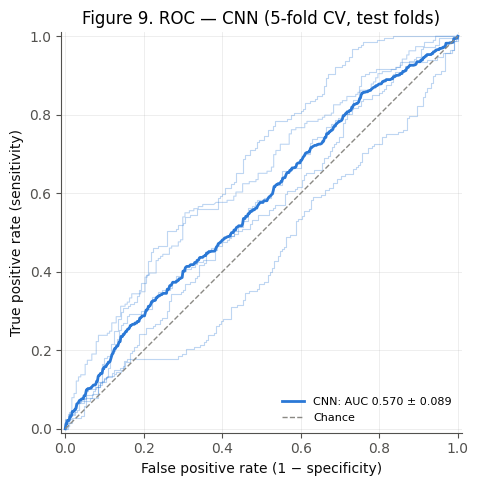

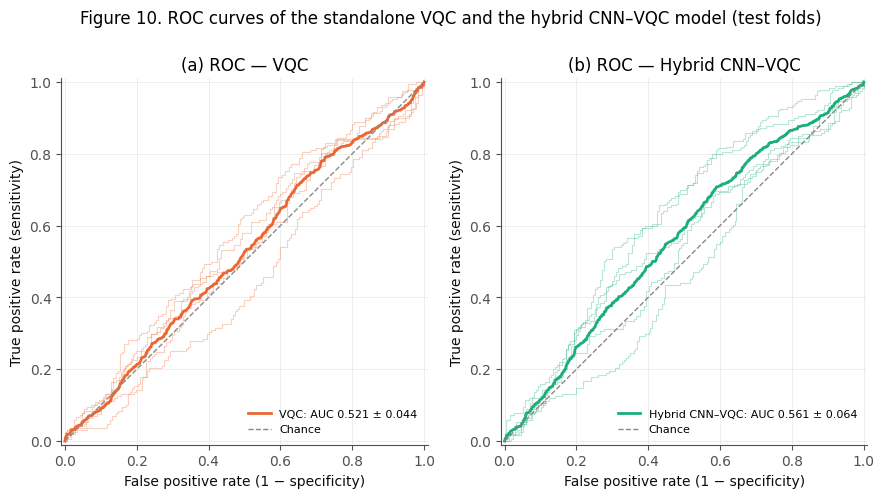

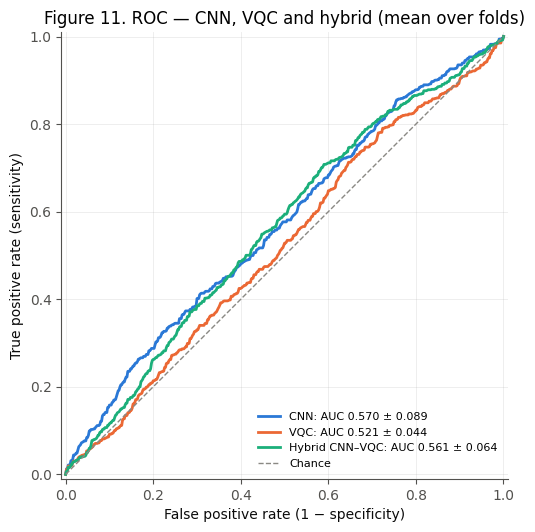

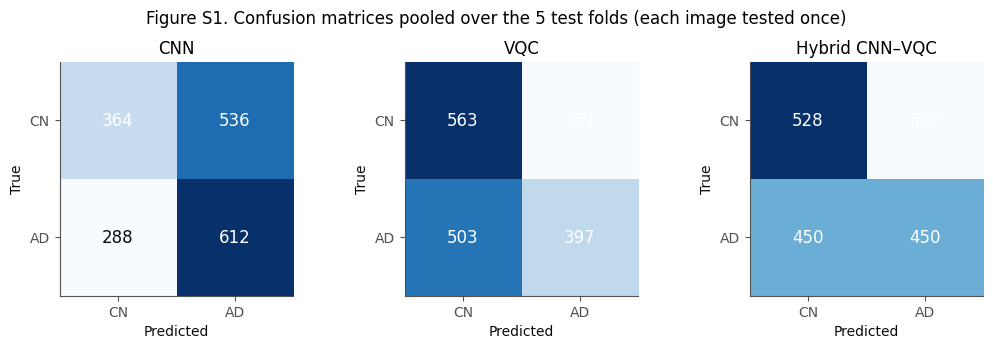

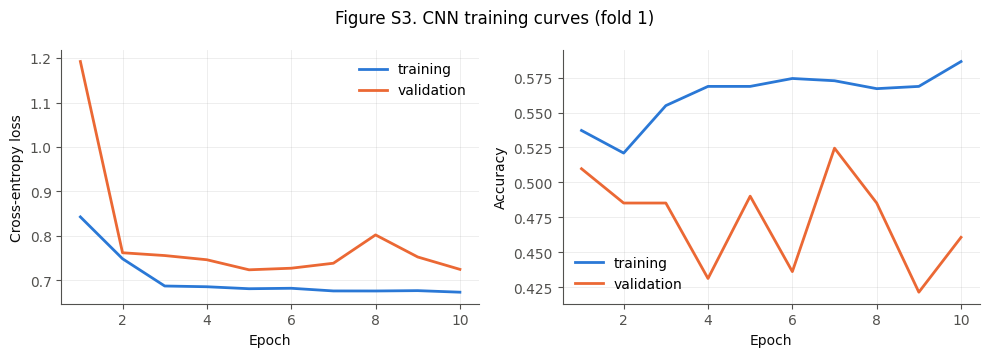

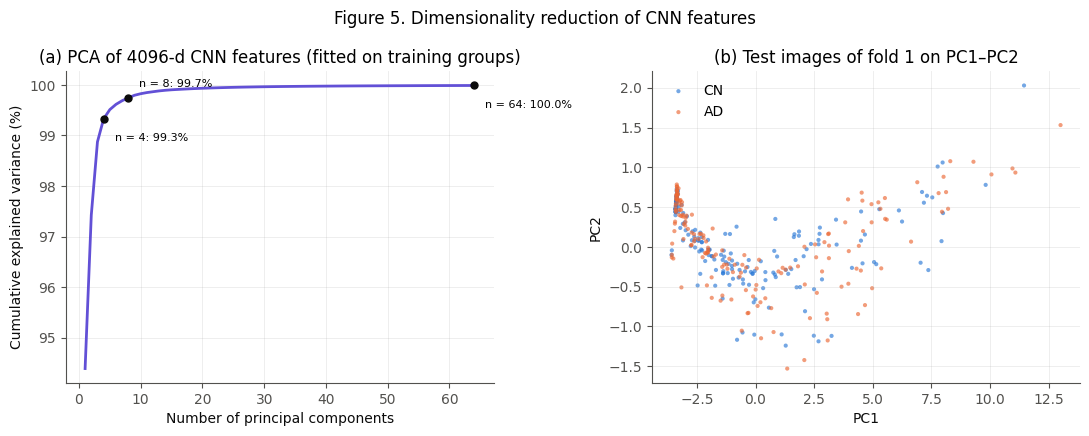

,n_qubits,cumulative_variance_pct,val_accuracy_mean,val_accuracy_sd,val_auc_mean,val_auc_sd,trainable_params,train_time_s
0,4,98.851997,55.372,1.868,0.565,0.047,22,4.751
1,5,99.147003,58.037,3.286,0.573,0.072,27,8.073
2,6,99.380997,56.034,8.135,0.563,0.095,32,12.421
3,7,99.521004,56.224,1.965,0.553,0.022,37,10.129
4,8,99.609001,52.811,5.103,0.517,0.071,42,14.160


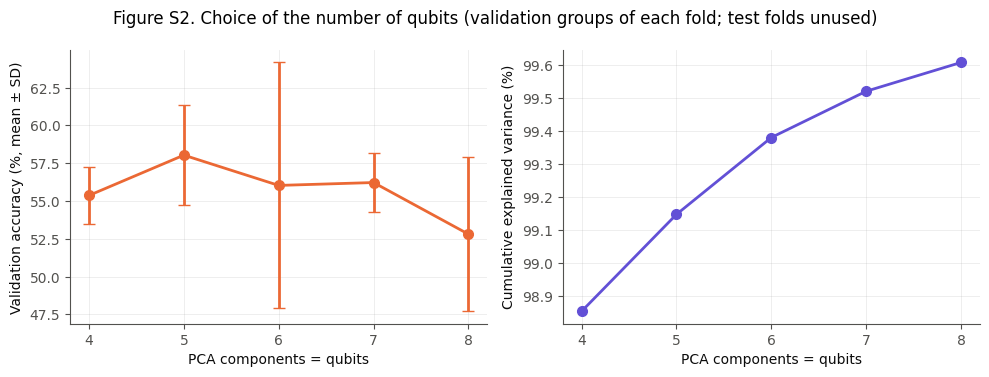

NOTE: n = 5 had the best mean validation accuracy. If you want to use it, set N_QUBITS = 5 and re-run; the choice uses validation data only.


In [13]:
def roc_panel(ax, m, folds_thin=True):
    grid, tprs = np.linspace(0, 1, 501), []
    for f in FOLDS:
        fpr, tpr, _ = roc_curve(y[f["test"]], P[m][f["test"]])
        if folds_thin:
            ax.plot(fpr, tpr, color=COLORS[m], lw=0.8, alpha=0.3)
        ti = np.interp(grid, fpr, tpr); ti[0] = 0; tprs.append(ti)
    mean = np.mean(tprs, 0); mean[-1] = 1
    ax.plot(grid, mean, color=COLORS[m], lw=2, label=f"{NAMES[m]}: AUC {fmt(m, 'auc')}")


def roc_style(ax, title):
    ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1, label="Chance")
    ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.01), xlabel="False positive rate (1 − specificity)",
           ylabel="True positive rate (sensitivity)", title=title)
    ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)


fig, ax = plt.subplots(figsize=(5.2, 5.2)); roc_panel(ax, "cnn")
roc_style(ax, f"Figure 9. ROC — CNN ({N_FOLDS}-fold CV, test folds)"); FIGS["fig09"] = savefig(fig, "fig09_roc_cnn")
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.2))
for ax, m, l in zip(axes, ("vqc", "hybrid"), "ab"):
    roc_panel(ax, m); roc_style(ax, f"({l}) ROC — {NAMES[m]}")
fig.suptitle("Figure 10. ROC curves of the standalone VQC and the hybrid CNN–VQC model (test folds)")
FIGS["fig10"] = savefig(fig, "fig10_roc_vqc_hybrid")
fig, ax = plt.subplots(figsize=(5.8, 5.8))
for m in ("cnn", "vqc", "hybrid"):
    roc_panel(ax, m, folds_thin=False)
roc_style(ax, "Figure 11. ROC — CNN, VQC and hybrid (mean over folds)"); FIGS["fig11"] = savefig(fig, "fig11_roc_all_models")

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, m in zip(axes, ("cnn", "vqc", "hybrid")):
    q = S[m]["pooled"]; cm = np.array([[q["tn"], q["fp"]], [q["fn"], q["tp"]]])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["CN", "AD"], yticklabels=["CN", "AD"],
           xlabel="Predicted", ylabel="True", title=f"{NAMES[m]}")
fig.suptitle(f"Figure S1. Confusion matrices pooled over the {N_FOLDS} test folds (each image tested once)")
fig.tight_layout(); FIGS["figS1"] = savefig(fig, "figS1_confusion_matrices")

h0 = HIST[HIST.fold == 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, met in zip(axes, ("loss", "acc")):
    ax.plot(h0.epoch, h0[f"train_{met}"], color=COLORS["cnn"], lw=2, label="training")
    ax.plot(h0.epoch, h0[f"val_{met}"], color=COLORS["vqc"], lw=2, label="validation")
    ax.set(xlabel="Epoch", ylabel="Cross-entropy loss" if met == "loss" else "Accuracy"); ax.legend()
fig.suptitle("Figure S3. CNN training curves (fold 1)"); fig.tight_layout()
FIGS["figS3"] = savefig(fig, "figS3_cnn_training_curves")

pca0 = KEEP["pca"]; cum0 = np.cumsum(pca0.explained_variance_ratio_) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(np.arange(1, N_PCA + 1), cum0, color="#6250d6", lw=2)
for j, n in enumerate(sorted({N_QUBITS, 8, N_PCA} & set(range(1, N_PCA + 1)))):
    axes[0].plot(n, cum0[n - 1], "o", color="#0b0b0b", ms=5)
    axes[0].annotate(f"n = {n}: {cum0[n - 1]:.1f}%", (n, cum0[n - 1]), xytext=(8, -16 if j % 2 == 0 else 8),
                     textcoords="offset points", fontsize=8)
axes[0].set(xlabel="Number of principal components", ylabel="Cumulative explained variance (%)",
            title="(a) PCA of 4096-d CNN features (fitted on training groups)")
Zp = KEEP["Z_te"][:, :2]; yte0 = y[KEEP["fold"]["test"]]
for lab in (0, 1):
    axes[1].scatter(Zp[yte0 == lab, 0], Zp[yte0 == lab, 1], s=9, alpha=0.65, color=CLASS_COLORS[lab],
                    label="CN" if lab == 0 else "AD", edgecolors="none")
axes[1].set(xlabel="PC1", ylabel="PC2", title="(b) Test images of fold 1 on PC1–PC2"); axes[1].legend()
fig.suptitle("Figure 5. Dimensionality reduction of CNN features"); fig.tight_layout()
FIGS["fig05"] = savefig(fig, "fig05_pca")

if RUN_QUBIT_SWEEP:
    SW = pd.DataFrame(SWEEP)
    TABLE8 = SW.groupby("n_qubits").agg(cumulative_variance_pct=("cumulative_variance_pct", "mean"),
                                        val_accuracy_mean=("val_accuracy", "mean"), val_accuracy_sd=("val_accuracy", "std"),
                                        val_auc_mean=("val_auc", "mean"), val_auc_sd=("val_auc", "std"),
                                        trainable_params=("trainable_params", "first"),
                                        train_time_s=("train_time_s", "mean")).reset_index()
    BEST_N = int(TABLE8.loc[TABLE8.val_accuracy_mean.idxmax(), "n_qubits"])
    TABLE8.round(3).to_csv(os.path.join(OUT_DIR, "tables", "table8_qubit_sweep.csv"), index=False)
    display(TABLE8.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].errorbar(TABLE8.n_qubits, TABLE8.val_accuracy_mean, yerr=TABLE8.val_accuracy_sd, fmt="o-",
                     color=COLORS["vqc"], lw=2, capsize=4, ms=7)
    axes[0].set(xlabel="PCA components = qubits", ylabel="Validation accuracy (%, mean ± SD)", xticks=TABLE8.n_qubits)
    axes[1].plot(TABLE8.n_qubits, TABLE8.cumulative_variance_pct, "o-", color="#6250d6", lw=2, ms=7)
    axes[1].set(xlabel="PCA components = qubits", ylabel="Cumulative explained variance (%)", xticks=TABLE8.n_qubits)
    fig.suptitle("Figure S2. Choice of the number of qubits (validation groups of each fold; test folds unused)")
    fig.tight_layout(); FIGS["figS2"] = savefig(fig, "figS2_qubit_sweep")
    if BEST_N != N_QUBITS:
        print(f"NOTE: n = {BEST_N} had the best mean validation accuracy. If you want to use it, set N_QUBITS = {BEST_N} "
              "and re-run; the choice uses validation data only.")

End-to-end hybrid vs pipeline predictions: max |dp| = 8.64e-06
{
 "n": 358,
 "r_mean": -0.0717,
 "r_sd": 0.4913,
 "r_median": -0.2051,
 "inside_cnn": 4.7806,
 "inside_hyb": 34.2197,
 "area": 35.9925,
 "e2e_diff": 0.0,
 "wilcoxon_p": 0.8361
}


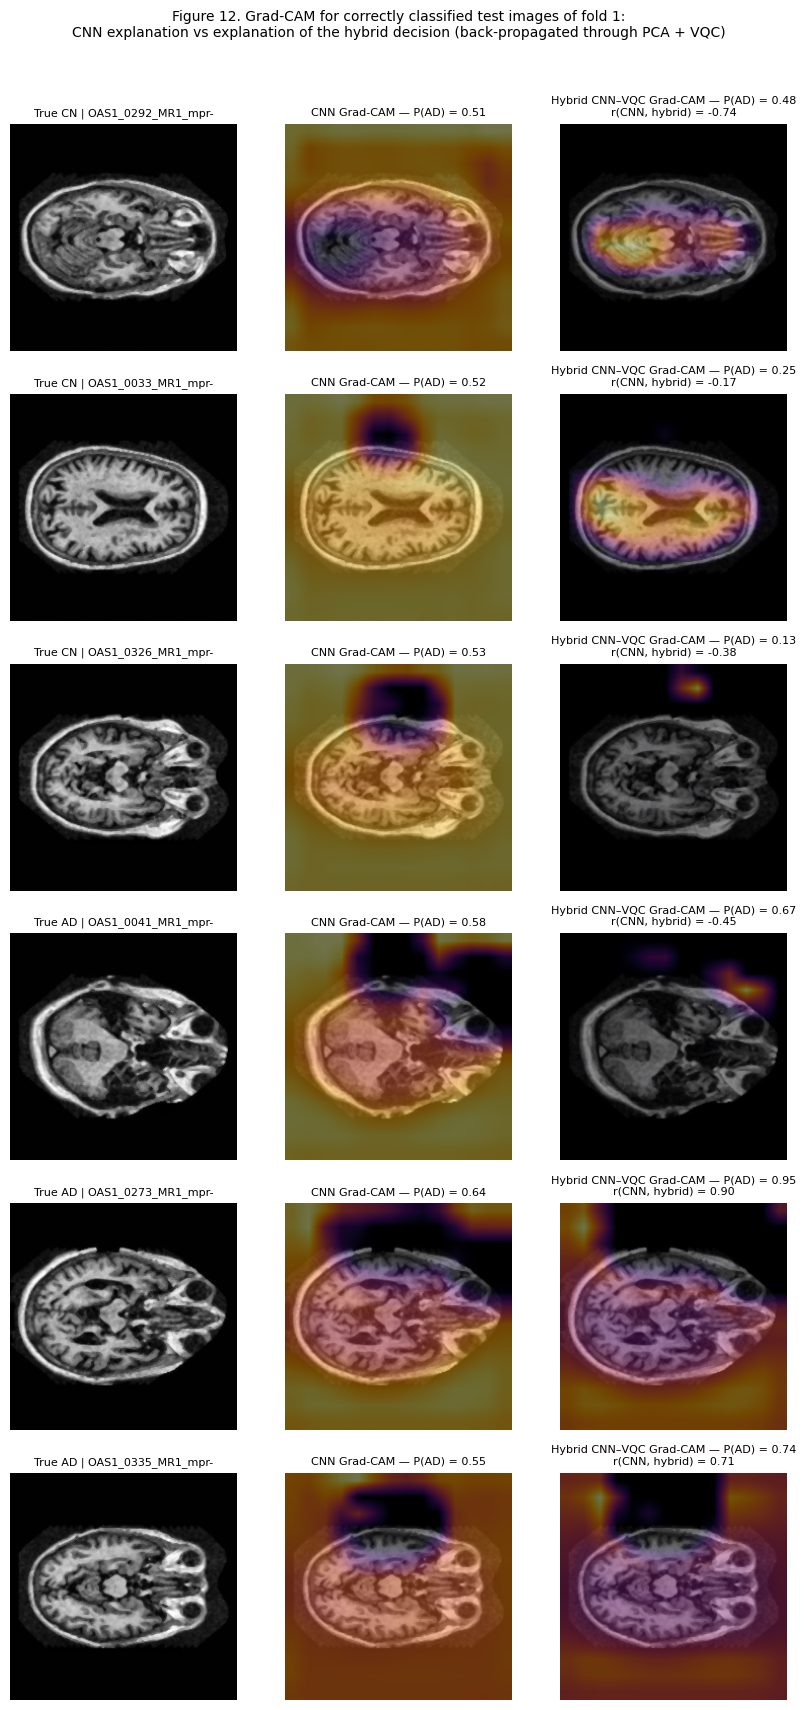

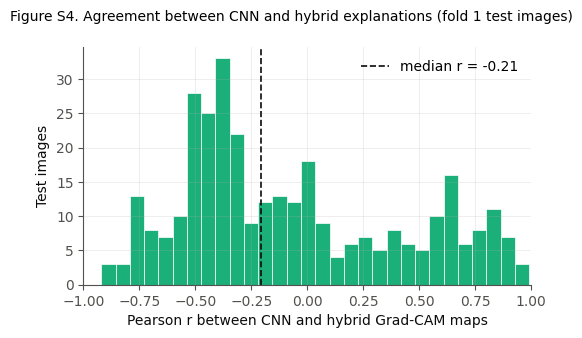

Grad-CAM agreement computed on 327 of 358 test images (constant maps skipped)


In [14]:
class HybridEndToEnd(nn.Module):
    """CNN conv maps -> fc1 -> PCA -> (standardised 64 comps, min-max scaled n comps -> VQC) -> softmax."""

    def __init__(self, cnn, pca, sc, mm, head):
        super().__init__()
        self.cnn, self.head = cnn, head
        f64 = lambda a: torch.tensor(np.asarray(a), dtype=torch.float64, device=DEVICE)   # float64 like scikit-learn
        self.register_buffer("pmean", f64(pca.mean_)); self.register_buffer("pW", f64(pca.components_.T))
        self.register_buffer("mu", f64(sc.mean_)); self.register_buffer("sd", f64(sc.scale_))
        self.register_buffer("qmin", f64(mm.data_min_)); self.register_buffer("qscale", f64(mm.scale_))

    def from_maps(self, A):
        z = (self.cnn.embed_from_maps(A).double() - self.pmean) @ self.pW
        zq = torch.clamp((z[:, :N_QUBITS] - self.qmin) * self.qscale, 0, math.pi)
        return self.head(((z - self.mu) / self.sd).float(), zq.float())


def gradcam(model_from_maps, cnn, idx, cls=None, bs=16):
    cams, preds = [], []
    for s in range(0, len(idx), bs):
        xb = to_batch(idx[s:s + bs])
        A = cnn.body(xb).detach().requires_grad_(True)
        logits = model_from_maps(A)
        c = logits.argmax(1) if cls is None else torch.full((len(xb),), cls, device=DEVICE)
        logits.gather(1, c[:, None]).sum().backward()
        w = A.grad.mean((2, 3), keepdim=True)
        cam = F.relu((w * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[:, 0]
        mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        cams.append(((cam - mn) / (mx - mn + 1e-12)).detach().cpu().numpy())
        preds.append(torch.softmax(logits, 1)[:, 1].detach().cpu().numpy())
    return np.concatenate(cams), np.concatenate(preds)


cnn0 = KEEP["cnn"].eval()
for prm in cnn0.parameters():
    prm.requires_grad_(False)
e2e = HybridEndToEnd(cnn0, KEEP["pca"], KEEP["sc"], KEEP["mm"], copy.deepcopy(KEEP["hyb"]).to(DEVICE).eval()).to(DEVICE).eval()
te0 = KEEP["fold"]["test"]
cam_cnn, pa_cnn = gradcam(lambda A: cnn0.fc2(cnn0.embed_from_maps(A)), cnn0, te0)
cam_hyb, pa_hyb = gradcam(e2e.from_maps, cnn0, te0)
# the end-to-end module must reproduce the hybrid predictions made from pre-computed features
E2E_MAX_DIFF = float(np.abs(pa_hyb - P["hybrid"][te0]).max())
print(f"End-to-end hybrid vs pipeline predictions: max |dp| = {E2E_MAX_DIFF:.2e}")

with np.errstate(invalid="ignore", divide="ignore"):   # constant (all-zero) maps give r = NaN and are skipped
    corr = np.array([np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(cam_cnn, cam_hyb)])
masks = np.stack([brain_mask(X[i]) for i in te0])


def inside_fraction(cams, top=0.2):
    out = []
    for c, m in zip(cams, masks):
        sel = c >= np.quantile(c, 1 - top)
        out.append((sel & m).sum() / max(sel.sum(), 1))
    return np.array(out)


in_cnn, in_hyb, area = inside_fraction(cam_cnn), inside_fraction(cam_hyb), masks.mean((1, 2))
GRADCAM = dict(n=len(te0), r_mean=float(np.nanmean(corr)), r_sd=float(np.nanstd(corr, ddof=1)),
               r_median=float(np.nanmedian(corr)), inside_cnn=100 * in_cnn.mean(), inside_hyb=100 * in_hyb.mean(),
               area=100 * area.mean(), e2e_diff=E2E_MAX_DIFF,
               wilcoxon_p=float(stats.wilcoxon(in_hyb, area, alternative="greater").pvalue) if len(te0) >= 10 else np.nan)
print(json.dumps({k: round(v, 4) for k, v in GRADCAM.items()}, indent=1))

yh_hyb = (P["hybrid"][te0] >= 0.5).astype(int)
ex, rng_ex = [], np.random.default_rng(SEED)
for lab in (0, 1):   # random (not hand-picked) correctly classified examples with non-constant maps
    ok_idx = np.where((y[te0] == lab) & (yh_hyb == lab) & np.isfinite(corr))[0]
    ex += list(rng_ex.choice(ok_idx, min(N_GRADCAM_EXAMPLES, len(ok_idx)), replace=False))
fig, axes = plt.subplots(len(ex), 3, figsize=(8.4, 2.9 * len(ex)))
axes = np.atleast_2d(axes)
for r_, j in enumerate(ex):
    i = te0[j]
    axes[r_, 0].imshow(X[i], cmap="gray")
    axes[r_, 0].set_title(f"True {'AD' if y[i] else 'CN'} | {Path(df.rel[i]).name[:18]}", fontsize=8)
    for c_, (cam, pa, lab) in enumerate(((cam_cnn[j], pa_cnn[j], "CNN"), (cam_hyb[j], pa_hyb[j], "Hybrid CNN–VQC")), 1):
        axes[r_, c_].imshow(X[i], cmap="gray")
        axes[r_, c_].imshow(cam, cmap="inferno", alpha=0.45, vmin=0, vmax=1)
        axes[r_, c_].set_title(f"{lab} Grad-CAM — P(AD) = {pa:.2f}" + (f"\nr(CNN, hybrid) = {corr[j]:.2f}" if c_ == 2 else ""),
                               fontsize=8)
    for a in axes[r_]:
        a.axis("off"); a.grid(False)
fig.suptitle("Figure 12. Grad-CAM for correctly classified test images of fold 1:\n"
             "CNN explanation vs explanation of the hybrid decision (back-propagated through PCA + VQC)", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.965)); FIGS["fig12"] = savefig(fig, "fig12_gradcam_cnn_vs_hybrid")

fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.hist(corr[np.isfinite(corr)], bins=30, color=COLORS["hybrid"], edgecolor="white", linewidth=0.5)
ax.axvline(GRADCAM["r_median"], color="#0b0b0b", lw=1.2, ls="--", label=f"median r = {GRADCAM['r_median']:.2f}")
ax.set(xlabel="Pearson r between CNN and hybrid Grad-CAM maps", ylabel="Test images", xlim=(-1, 1)); ax.legend()
fig.suptitle("Figure S4. Agreement between CNN and hybrid explanations (fold 1 test images)", fontsize=10)
fig.tight_layout(); FIGS["figS4"] = savefig(fig, "figS4_gradcam_agreement")
print(f"Grad-CAM agreement computed on {int(np.isfinite(corr).sum())} of {len(corr)} test images (constant maps skipped)")

In [15]:
hyb0 = KEEP["hyb"].eval()
theta0 = hyb0.q.theta.detach().cpu().numpy().astype(np.float64)
q_te0 = KEEP["q_te"].astype(np.float64)
Z_qiskit = qiskit_expectations(N_QUBITS, q_te0, theta0)
with torch.no_grad():
    Z_torch = hyb0.q(torch.tensor(q_te0, dtype=torch.float32, device=Q_DEVICE)).cpu().numpy()
C_te0 = torch.tensor(KEEP["C_te"], dtype=torch.float32, device=Q_DEVICE)


@torch.no_grad()
def hybrid_from_z(Zq):
    return torch.softmax(hyb0.out(torch.cat([C_te0, torch.tensor(Zq, dtype=torch.float32, device=Q_DEVICE)], 1)), 1)[:, 1].cpu().numpy()


p_qiskit_exact = hybrid_from_z(Z_qiskit)
QISKIT_CHECK = dict(max_abs_z_diff=float(np.abs(Z_qiskit - Z_torch).max()),
                    max_abs_p_diff=float(np.abs(p_qiskit_exact - P["hybrid"][te0]).max()),
                    prediction_agreement_pct=100 * float(np.mean((p_qiskit_exact >= 0.5) == (P["hybrid"][te0] >= 0.5))))
print("Qiskit Statevector vs PyTorch on fold-1 test set:", QISKIT_CHECK)

qc_m = QC.copy(); qc_m.measure_all()
sampler_params = {tuple(QC_X): q_te0, tuple(QC_T): np.tile(theta0, (len(q_te0), 1))}
y0 = y[te0]
shot_rows = [dict(shots="exact (statevector)", seed=-1, accuracy=100 * float(np.mean((p_qiskit_exact >= 0.5) == y0)),
                  auc=float(roc_auc_score(y0, p_qiskit_exact)), mean_abs_dp=0.0, flipped_predictions=0)]
for shots in SHOTS_LIST:
    for s in range(N_SHOT_SEEDS):
        res = StatevectorSampler(default_shots=shots, seed=SEED + s).run([(qc_m, sampler_params)]).result()[0]
        bits = res.data.meas.array          # (N, shots, bytes) — little-endian: qubit k = bit k
        vals = np.zeros(bits.shape[:-1], dtype=np.int64)
        for b in range(bits.shape[-1]):
            vals = (vals << 8) | bits[..., b].astype(np.int64)
        Zs = np.stack([1 - 2 * ((vals >> k) & 1).mean(-1) for k in range(N_QUBITS)], 1)
        ps = hybrid_from_z(Zs)
        shot_rows.append(dict(shots=shots, seed=s, accuracy=100 * float(np.mean((ps >= 0.5) == y0)),
                              auc=float(roc_auc_score(y0, ps)), mean_abs_dp=float(np.abs(ps - p_qiskit_exact).mean()),
                              flipped_predictions=int(np.sum((ps >= 0.5) != (p_qiskit_exact >= 0.5)))))
SHOT = pd.DataFrame(shot_rows)
SHOT_SUM = SHOT.groupby("shots", sort=False).agg(accuracy_mean=("accuracy", "mean"), accuracy_sd=("accuracy", "std"),
                                                 auc_mean=("auc", "mean"), mean_abs_dp=("mean_abs_dp", "mean"),
                                                 flipped_predictions=("flipped_predictions", "mean")).reset_index()
SHOT_SUM.round(4).to_csv(os.path.join(OUT_DIR, "tables", "tableS_shot_noise.csv"), index=False)
display(SHOT_SUM.round(4))

Qiskit Statevector vs PyTorch on fold-1 test set: {'max_abs_z_diff': 2.441909729089531e-06, 'max_abs_p_diff': 3.2782554626464844e-07, 'prediction_agreement_pct': 100.0}


,shots,accuracy_mean,accuracy_sd,auc_mean,mean_abs_dp,flipped_predictions
0,exact (statevector),50.8380,NaN,0.5305,0.0000,0.0
1,128,51.0615,0.7751,0.5304,0.0196,11.6
2,1024,50.8939,0.2337,0.5302,0.0063,5.4
3,8192,50.7821,0.2337,0.5300,0.0021,0.6


In [16]:
TABLE6 = pd.DataFrame([
    ("Input", f"{IMG_SIZE} × {IMG_SIZE} × 1 (greyscale), median filter 3×3, CLAHE (2.0, 8×8), min–max normalisation"),
    ("Augmentation (training only)", "horizontal flip; random affine: ±10°, ±5% translation, 0.95–1.05 scale"),
    ("CNN", f"{len(CNN_WIDTHS)} blocks [2 × (3×3 conv, BN, ReLU) + 2×2 max-pool], filters {list(CNN_WIDTHS)}; "
            f"adaptive avg-pool 2×2; FC {FEATURE_DIM} (ReLU, dropout {CNN_DROPOUT}); FC 2 (softmax)"),
    ("CNN parameters", f"{N_PARAMS['cnn_total']:,} total ({N_PARAMS['cnn_classification_part']:,} in the FC layers)"),
    ("CNN training", f"Adam, lr {CNN_LR}, batch {BATCH_SIZE}, ≤ {CNN_EPOCHS} epochs, early stopping (patience {CNN_PATIENCE}) "
                     f"on validation loss; epochs used {TIMES.cnn_epochs.min()}–{TIMES.cnn_epochs.max()}"),
    ("Feature vector", f"{FEATURE_DIM}-d output of the first FC layer"),
    ("PCA", f"fitted on training groups only; {N_PCA} components ({cum0[N_PCA - 1]:.1f}% variance, fold 1); "
            f"leading {N_QUBITS} ({cum0[N_QUBITS - 1]:.1f}%) to the VQC"),
    ("Quantum encoding", f"{'ZZ feature map, ' + str(FM_REPS) + ' repetitions' if ENCODING == 'zz' else 'RY angle encoding'}; "
                         "inputs min–max scaled to [0, π] on training groups"),
    ("Ansatz", f"RealAmplitudes, {ANSATZ_REPS} layers, {ENTANGLEMENT} CNOT entanglement"),
    ("Qubits / trainable quantum parameters", f"{N_QUBITS} / {len(QC_T)}"),
    ("Circuit depth / CNOTs (H, P, CX, RY gates)", f"{CIRCUIT_INFO['depth']} / {CIRCUIT_INFO['cx_gates']}"),
    ("Measurement", "⟨Z_k⟩ on every qubit (Eq. 13)"),
    ("VQC classifier", f"⟨Z⟩ → linear softmax; {N_PARAMS['vqc_total']} trainable parameters"),
    ("Hybrid head (Eq. 14–15)", f"[standardised {N_PCA} PCA comps ⊕ {N_QUBITS} ⟨Z⟩ values] → linear softmax; "
                                f"{N_PARAMS['hybrid_head_total']} trainable parameters; CNN frozen"),
    ("Quantum/hybrid training", f"Adam, lr {Q_LR}, batch {Q_BATCH}, ≤ {Q_EPOCHS} epochs, early stopping (patience {Q_PATIENCE}); "
                                f"best of {Q_RESTARTS} random initialisations by validation loss; "
                                "exact gradients (automatic differentiation of the state vector)"),
    ("Simulation", "exact state vector (PyTorch, complex64), verified against Qiskit Statevector "
                   f"(max |Δ⟨Z⟩| = {max(SIM_CHECK.values()):.1e} random; {QISKIT_CHECK['max_abs_z_diff']:.1e} on test data)"),
    ("Data", f"OASIS-1 (Kaggle 2D axial slices); AD = CDR ≥ {AD_MIN_CDR:g}, CN = CDR 0" + (f", age ≥ {CN_MIN_AGE}" if AGE_MATCHED else "")
             + f"; one session/acquisition per subject; {df.groupby('subject').size().min()}–{df.groupby('subject').size().max()} "
             "slices per subject"),
    ("Evaluation", f"{N_FOLDS}-fold stratified cross-validation at subject level; {int(VAL_FRAC * 100)}% of the subjects of "
                   "each training fold held out for early stopping and qubit selection"),
    ("Training time (mean per fold)", f"CNN {TIME_MEAN['cnn']:.1f} min; VQC {TIME_MEAN['vqc']:.2f} min; hybrid head {TIME_MEAN['hybrid']:.2f} min"),
    ("Software / hardware", f"Python {ENV['python']}, PyTorch {ENV['torch']}, Qiskit {ENV['qiskit']}, "
                            f"scikit-learn {ENV['scikit-learn']}; {ENV['device']}"),
], columns=["Component", "Setting"])
TABLE6.to_csv(os.path.join(OUT_DIR, "tables", "table6_hyperparameters.csv"), index=False)
pd.set_option("display.max_colwidth", 200)
display(TABLE6)

,Component,Setting
0,Input,"224 × 224 × 1 (greyscale), median filter 3×3, CLAHE (2.0, 8×8), min–max normalisation"
1,Augmentation (training only),"horizontal flip; random affine: ±10°, ±5% translation, 0.95–1.05 scale"
2,CNN,"5 blocks [2 × (3×3 conv, BN, ReLU) + 2×2 max-pool], filters [32, 64, 128, 256, 256]; adaptive avg-pool 2×2; FC 4096 (ReLU, dropout 0.5); FC 2 (softmax)"
3,CNN parameters,"6,559,906 total (4,206,594 in the FC layers)"
4,CNN training,"Adam, lr 0.001, batch 16, ≤ 20 epochs, early stopping (patience 5) on validation loss; epochs used 7–14"
5,Feature vector,4096-d output of the first FC layer
6,PCA,"fitted on training groups only; 64 components (100.0% variance, fold 1); leading 4 (99.3%) to the VQC"
7,Quantum encoding,"ZZ feature map, 2 repetitions; inputs min–max scaled to [0, π] on training groups"
8,Ansatz,"RealAmplitudes, 2 layers, linear CNOT entanglement"
9,Qubits / trainable quantum parameters,4 / 12


In [17]:
def pfmt(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


def sig(p):
    return "statistically significant" if p < 0.05 else "not statistically significant"


def compare(a, b, tol=0.5):
    d = S[a]["accuracy"] - S[b]["accuracy"]
    return "higher than" if d > tol else ("lower than" if d < -tol else "comparable to")


nCN, nAD = int((y == 0).sum()), int((y == 1).sum())
st_ch, st_hl, st_vl = ST["cnn|hybrid"], ST["hybrid|lin64"], ST["vqc|lin_n"]
ss_ch, ss_hl = SUBJ_STATS["cnn|hybrid"], SUBJ_STATS["hybrid|lin64"]
hyb_better = st_ch.paired_t_acc_p < 0.05 and ss_ch["p"] < 0.05 and S["hybrid"]["accuracy"] > S["cnn"]["accuracy"]
q_adds = ss_hl["p"] < 0.05 and S["hybrid"]["accuracy"] > S["lin64"]["accuracy"]
n_sub = {lab: df[df.label == lab].subject.nunique() for lab in (0, 1)}
spp = df.groupby("subject").size()
k_desc = f"{spp.min()}" if spp.min() == spp.max() else f"{spp.min()}–{spp.max()}"
cdr_counts = ", ".join(f"CDR {c:g}: {n}" for c, n in sel_subj[sel_subj.label == 1].cdr.value_counts().sort_index().items())
if DEMO is not None:
    demo_txt = (f" Age (mean ± SD) was {DEMO_TESTS['age_cn']} years in the CN group and {DEMO_TESTS['age_ad']} years in the "
                f"AD group (Welch t-test p = {DEMO_TESTS['age_p']:.3f}; sex: χ² p = {DEMO_TESTS.get('sex_p', np.nan):.3f}); "
                f"MMSE was {DEMO_TESTS['mmse_cn']} and {DEMO_TESTS['mmse_ad']}, respectively.")
    if DEMO_TESTS["age_p"] < 0.05:
        demo_txt += " The groups still differed in age, which should be considered when interpreting the results."
else:
    demo_txt = ""

R = []
R.append(("h1", "Additions to Section 3.1 (Dataset)"))
R.append(("p", f"The experiments used {DATASET_NAME} {DATASET_CITATION}. OASIS-1 comprises T1-weighted MRI of 416 adults "
               "aged 18–96 years, 100 of whom have very mild to moderate dementia of the Alzheimer type; the Kaggle version "
               f"provides axial slices {SLICE_RANGE[0]}–{SLICE_RANGE[1]} of each scan, labelled by Clinical Dementia Rating (CDR). "
               f"AD was defined as CDR ≥ {AD_MIN_CDR:g} ({n_sub[1]} subjects; {cdr_counts}) and cognitively normal (CN) as CDR 0"
               + (f" with age ≥ {CN_MIN_AGE} years, because all OASIS-1 dementia cases are older than 60 ({n_sub[0]} subjects)"
                  if AGE_MATCHED else f" ({n_sub[0]} subjects; not age-matched)")
               + f". For each subject, one session (MR1) and one T1-weighted acquisition were used, and {k_desc} evenly spaced "
               f"slices were selected, giving {len(y)} images ({nCN} CN, {nAD} AD; Table 1).{demo_txt}"))
R.append(("p", f"Performance was estimated with {N_FOLDS}-fold stratified cross-validation at the subject level: all images of "
               "a subject were assigned to the same fold, and no subject contributed images to more than one of the training, "
               "validation and test sets (verified programmatically). Within each training fold, "
               f"{int(VAL_FRAC * 100)}% of the subjects were held out as a validation set for early stopping and for choosing "
               "the number of qubits; the test fold was never used for training or model selection."))
R.append(("table", TABLE1, "Table 1. Selected subjects and images (OASIS-1)."))
R.append(("h1", "4. Experimental Results"))
R.append(("p", f"Each of the {len(y)} images (and each of the {len(ys)} subjects) was tested exactly once. Image-level results "
               f"are reported as mean ± standard deviation over the {N_FOLDS} test folds; pooled 95% confidence intervals were "
               f"obtained by bootstrap resampling of subjects ({N_BOOTSTRAP} resamples). Subject-level results use the mean "
               "predicted probability over each subject's slices. A threshold of 0.5 on the predicted probability of AD was used."))
R.append(("h2", "4.2 CNN Model Performance"))
R.append(("p", f"The CNN achieved an accuracy of {fmt('cnn', 'accuracy')}% (pooled 95% CI {S['cnn']['acc_ci'][0]:.1f}–"
               f"{S['cnn']['acc_ci'][1]:.1f}%), a sensitivity of {fmt('cnn', 'recall')}%, a specificity of "
               f"{fmt('cnn', 'specificity')}% and an AUC of {fmt('cnn', 'auc')} (Table 3, Figure 9)."))
R.append(("table", TABLES["table3_cnn"], "Table 3. CNN performance (test folds)."))
R.append(("fig", FIGS["fig09"], "Figure 9. Empirical ROC curves of the CNN (thin: individual folds; thick: mean)."))
R.append(("h2", "4.3 VQC Model Performance"))
R.append(("p", f"The standalone VQC, operating on the leading {N_QUBITS} PCA components encoded on {N_QUBITS} qubits "
               f"({len(QC_T)} trainable circuit parameters; {N_PARAMS['vqc_total']} in total), achieved an accuracy of "
               f"{fmt('vqc', 'accuracy')}% and an AUC of {fmt('vqc', 'auc')} (Table 4, Figure 10a). A classical linear "
               f"classifier given the same {N_QUBITS} components achieved {fmt('lin_n', 'accuracy')}% (AUC {fmt('lin_n', 'auc')}); "
               f"the difference was {sig(st_vl.mcnemar_p)} (McNemar p {pfmt(st_vl.mcnemar_p)})."))
R.append(("table", TABLES["table4_vqc"], "Table 4. VQC performance (test folds)."))
R.append(("h2", "4.4 Comparative Analysis: CNN, VQC and Hybrid CNN–VQC"))
R.append(("p", f"Table 5 compares all models. The hybrid CNN–VQC model achieved an accuracy of {fmt('hybrid', 'accuracy')}% and "
               f"an AUC of {fmt('hybrid', 'auc')}, {compare('hybrid', 'cnn')} the classical CNN ({fmt('cnn', 'accuracy')}%; AUC "
               f"{fmt('cnn', 'auc')}). The difference was {sig(ss_ch['p'])} by McNemar's exact test on subject-level "
               f"predictions (p {pfmt(ss_ch['p'])}) and {sig(st_ch.paired_t_acc_p)} by a paired t-test on fold accuracies "
               f"(p {pfmt(st_ch.paired_t_acc_p)}); the DeLong test on image-level AUCs gave p {pfmt(st_ch.delong_p)}, but it treats "
               "correlated slices of the same subject as independent and is therefore optimistic. "
               f"Removing the quantum branch from the hybrid head (a linear classifier on the same {N_PCA} components) gave "
               f"{fmt('lin64', 'accuracy')}% (AUC {fmt('lin64', 'auc')}), so the VQC branch "
               + ("significantly improved" if q_adds else "did not significantly change")
               + f" the classification (subject-level McNemar p {pfmt(ss_hl['p'])})."))
R.append(("table", TABLES["table5_comparison"], "Table 5. Comparison of all models (mean ± SD over test folds)."))
R.append(("p", "The hybrid model therefore " + ("outperformed" if hyb_better else "did not outperform")
               + " the classical CNN in this experiment. Because all quantum circuits were simulated on classical hardware, "
               "these results do not indicate a quantum computational advantage; they show whether a compact quantum "
               f"classifier ({len(QC_T)} circuit parameters) can be combined with CNN features while maintaining diagnostic "
               "performance. ROC curves are shown in Figures 10 and 11."))
R.append(("fig", FIGS["fig10"], "Figure 10. Empirical ROC curves of (a) the VQC and (b) the hybrid CNN–VQC model."))
R.append(("fig", FIGS["fig11"], "Figure 11. Mean ROC curves of the CNN, VQC and hybrid CNN–VQC models."))
R.append(("p", f"At the subject level ({len(ys)} subjects), accuracies were "
               + "; ".join(f"{NAMES[m]} {SUBJ[m]['accuracy']:.1f}% (AUC {SUBJ[m]['auc']:.3f})" for m in ("cnn", "vqc", "hybrid"))
               + " (Table 5b)."))
R.append(("table", TABLE_SUBJ, "Table 5b. Subject-level performance (mean slice probability per subject)."))
R.append(("p", "Practical implications. " + (
    "At its current stage, the hybrid model offers no practical advantage to clinicians over the classical CNN, which "
    "achieved similar or higher performance with a simpler implementation. " if not hyb_better else
    "Although the hybrid model achieved higher accuracy than the CNN in this experiment, the circuits were simulated "
    "classically and only one dataset was used, so no practical clinical advantage can yet be claimed. ")
    + "Any clinical benefit would depend on validation in independent multi-site cohorts, extension to MCI, evaluation on "
      "quantum hardware and prospective assessment of the explanations by clinicians."))
R.append(("h2", "4.5 Explainability Analysis using Grad-CAM"))
R.append(("p", "Grad-CAM maps were computed in two ways for the test images of fold 1: from the CNN's own output, and from the "
               "hybrid model's output, back-propagated through the softmax layer, the VQC, the fixed scaling and PCA "
               "projection and the CNN to the last convolutional block. The second map therefore explains the hybrid "
               f"decision directly. Across {GRADCAM['n']} test images, the two maps were "
               + ("strongly" if GRADCAM["r_median"] >= 0.7 else "moderately" if GRADCAM["r_median"] >= 0.4 else "weakly")
               + f" correlated (Pearson r = {GRADCAM['r_mean']:.2f} ± {GRADCAM['r_sd']:.2f}; median {GRADCAM['r_median']:.2f}). "
               f"For the hybrid model, {GRADCAM['inside_hyb']:.1f}% of the top-20% activation fell inside the brain mask, "
               f"compared with {GRADCAM['area']:.1f}% expected from the mask area alone"
               + (", i.e. attention was concentrated inside the brain" if GRADCAM["inside_hyb"] > GRADCAM["area"] + 5 else
                  " — attention was not concentrated inside the brain, which suggests possible reliance on background "
                  "or image-border cues and should be investigated")
               + ". Representative, randomly selected correctly classified examples are shown in Figure 12. [Describe what YOUR maps show anatomically, e.g. which structures are highlighted in AD cases.] "
               "This analysis is qualitative with respect to anatomy: no comparison with atlas-defined regions was performed, "
               "so the maps should not be interpreted as validated biomarkers."))
R.append(("fig", FIGS["fig12"], "Figure 12. Grad-CAM of the CNN and of the hybrid CNN–VQC decision for representative CN and AD test images."))
R.append(("h2", "4.6 Simulation Fidelity and Measurement Noise"))
shot_hi, shot_lo = SHOT_SUM.iloc[-1], SHOT_SUM.iloc[1]
R.append(("p", f"Evaluating the trained circuit with Qiskit's Statevector reproduced the PyTorch simulation (maximum "
               f"|Δ⟨Z⟩| = {QISKIT_CHECK['max_abs_z_diff']:.1e}; {QISKIT_CHECK['prediction_agreement_pct']:.1f}% identical "
               "predictions). With finite measurement statistics, the hybrid model's test accuracy was "
               f"{shot_lo.accuracy_mean:.1f} ± {shot_lo.accuracy_sd:.1f}% with {shot_lo.shots} shots and "
               f"{shot_hi.accuracy_mean:.1f} ± {shot_hi.accuracy_sd:.1f}% with {shot_hi.shots} shots, compared with "
               f"{SHOT_SUM.iloc[0].accuracy_mean:.1f}% for the exact expectation values; on average "
               f"{shot_lo.flipped_predictions:.1f} of {len(te0)} predictions changed with {shot_lo.shots} shots (mean |Δp| = "
               f"{shot_lo.mean_abs_dp:.4f}). Finite sampling therefore adds statistical error to the estimated expectation "
               "values" + (" and did not improve accuracy" if shot_lo.accuracy_mean <= SHOT_SUM.iloc[0].accuracy_mean + 0.5 else "")
               + "; it is not a mechanism for robust prediction."))
R.append(("h2", "4.7 Limitations"))
R.append(("p", "First, all quantum circuits were simulated without hardware noise; performance on current quantum devices was not "
               "evaluated. Second, no computational speed-up or quantum advantage is claimed. Third, OASIS-1 is a single-site "
               f"dataset with {len(ys)} subjects in this analysis and binary CN-vs-AD classification; generalisation to "
               "independent multi-site cohorts (e.g., ADNI, AIBL) and to MCI has not been established. Fourth, slices from the "
               "same subject are correlated, so image-level statistics overstate the effective sample size; subject-level results "
               "are therefore also reported. "
               + ("" if AGE_MATCHED else "Fifth, the CN group was not age-matched and includes younger adults, so differences "
                  "in age may contribute to the classification. ")
               + "Finally, the model operates on 2D slices rather than full 3D volumes."))
R.append(("h1", "Additions to Section 3.4 (Choice of the number of qubits)"))
if RUN_QUBIT_SWEEP:
    b8 = TABLE8.set_index("n_qubits").loc[BEST_N]
    R.append(("p", f"Each principal component is encoded on one qubit, so the number of components fixes the circuit width. "
                   f"We evaluated n = {min(SWEEP_QUBITS)}–{max(SWEEP_QUBITS)} on the validation groups of each training fold "
                   f"(Table 8). n = {BEST_N} gave the highest mean validation accuracy ({b8.val_accuracy_mean:.1f} ± "
                   f"{b8.val_accuracy_sd:.1f}%, AUC {b8.val_auc_mean:.3f}) and retains {b8.cumulative_variance_pct:.1f}% of the "
                   f"variance of the CNN features. The reported models use n = {N_QUBITS}."))
    R.append(("table", TABLE8.round(3), "Table 8. VQC validation performance versus number of PCA components / qubits "
              "(mean ± SD over the validation groups of the training folds; one initialisation per setting)."))
R.append(("table", TABLE6, "Table 6. Implementation details and hyperparameters."))

def blocks_to_md(blocks):
    out = []
    for b in blocks:
        if b[0] == "h1": out += [f"# {b[1]}", ""]
        elif b[0] == "h2": out += [f"## {b[1]}", ""]
        elif b[0] == "p": out += [b[1], ""]
        elif b[0] == "table":
            t = b[1]; out += [f"**{b[2]}**", "", "| " + " | ".join(map(str, t.columns)) + " |", "|" + "---|" * len(t.columns)]
            out += ["| " + " | ".join(map(str, r)) + " |" for r in t.values.tolist()] + [""]
        elif b[0] == "fig": out += [f"![]({os.path.relpath(b[1], OUT_DIR)})", f"*{b[2]}*", ""]
    return "\n".join(out)


banner = (f"_Auto-generated by the QE-XAI notebook on {datetime.date.today():%d %b %Y}. "
          + ("**FAST_DEV_RUN — NOT FOR PUBLICATION.** " if FAST_DEV_RUN else "")
          + "Every number below was computed in this run._\n\n")
MD = banner + blocks_to_md(R)
with open(os.path.join(OUT_DIR, "results_section.md"), "w", encoding="utf-8") as f:
    f.write(MD)
try:
    from docx import Document
    from docx.shared import Inches, Pt
    doc = Document(); doc.styles["Normal"].font.name = "Times New Roman"; doc.styles["Normal"].font.size = Pt(11)
    doc.add_paragraph(banner.strip("_\n").replace("**", ""))
    for b in R:
        if b[0] in ("h1", "h2"): doc.add_heading(b[1], level=1 if b[0] == "h1" else 2)
        elif b[0] == "p": doc.add_paragraph(b[1])
        elif b[0] == "table":
            doc.add_paragraph(b[2]).runs[0].bold = True
            t = doc.add_table(rows=1, cols=len(b[1].columns)); t.style = "Table Grid"
            for i, c in enumerate(b[1].columns): t.rows[0].cells[i].text = str(c)
            for r in b[1].values.tolist():
                cells = t.add_row().cells
                for i, v in enumerate(r): cells[i].text = str(v)
        elif b[0] == "fig":
            doc.add_picture(b[1], width=Inches(6.2)); doc.add_paragraph(b[2]).runs[0].italic = True
    doc.save(os.path.join(OUT_DIR, "results_section.docx"))
except ImportError:
    print("python-docx not available — Markdown version only")
display(Markdown(MD.replace("![](", f"![]({os.path.relpath(OUT_DIR, os.getcwd())}/")))

_Auto-generated by the QE-XAI notebook on 12 Oct 2026. Every number below was computed in this run._

# Additions to Section 3.1 (Dataset)

The experiments used the OASIS-1 cross-sectional MRI data (Marcus et al., 2007) in the 2D-slice version distributed on Kaggle as “OASIS Alzheimer's Detection” [cite: Marcus et al., 2007; https://www.kaggle.com/datasets/ninadaithal/imagesoasis]. OASIS-1 comprises T1-weighted MRI of 416 adults aged 18–96 years, 100 of whom have very mild to moderate dementia of the Alzheimer type; the Kaggle version provides axial slices 100–160 of each scan, labelled by Clinical Dementia Rating (CDR). AD was defined as CDR ≥ 0.5 (81 subjects; CDR 0.5: 58, CDR 1: 21, CDR 2: 2) and cognitively normal (CN) as CDR 0 with age ≥ 60 years, because all OASIS-1 dementia cases are older than 60 (85 subjects). For each subject, one session (MR1) and one T1-weighted acquisition were used, and 10–12 evenly spaced slices were selected, giving 1800 images (900 CN, 900 AD; Table 1). Age (mean ± SD) was 76.4 ± 8.9 years in the CN group and 76.7 ± 7.3 years in the AD group (Welch t-test p = 0.794; sex: χ² p = 0.169); MMSE was 29.0 ± 1.2 and 24.1 ± 4.3, respectively.

Performance was estimated with 5-fold stratified cross-validation at the subject level: all images of a subject were assigned to the same fold, and no subject contributed images to more than one of the training, validation and test sets (verified programmatically). Within each training fold, 15% of the subjects were held out as a validation set for early stopping and for choosing the number of qubits; the test fold was never used for training or model selection.

**Table 1. Selected subjects and images (OASIS-1).**

| Group | Subjects | Images | CDR | Age (years) | Sex (F/M) | MMSE |
|---|---|---|---|---|---|---|
| CN | 85 | 900 | 0: 85 | 76.4 ± 8.9 (60–94) | 62/23 | 29.0 ± 1.2 |
| AD | 81 | 900 | 0.5: 58, 1: 21, 2: 2 | 76.7 ± 7.3 (62–96) | 50/31 | 24.1 ± 4.3 |
| p (CN vs AD) |  |  |  | 0.794 | 0.169 | 5.92e-16 |

# 4. Experimental Results

Each of the 1800 images (and each of the 166 subjects) was tested exactly once. Image-level results are reported as mean ± standard deviation over the 5 test folds; pooled 95% confidence intervals were obtained by bootstrap resampling of subjects (1000 resamples). Subject-level results use the mean predicted probability over each subject's slices. A threshold of 0.5 on the predicted probability of AD was used.

## 4.2 CNN Model Performance

The CNN achieved an accuracy of 54.2 ± 5.3% (pooled 95% CI 48.2–59.9%), a sensitivity of 67.5 ± 38.8%, a specificity of 40.2 ± 42.9% and an AUC of 0.570 ± 0.089 (Table 3, Figure 9).

**Table 3. CNN performance (test folds).**

| Metric | Mean ± SD over folds | Pooled (95% CI) |
|---|---|---|
| Accuracy (%) | 54.2 ± 5.3 | 54.2 (48.2–59.9) |
| Precision (%) | 55.5 ± 8.5 | 53.3 |
| Recall / sensitivity (%) | 67.5 ± 38.8 | 68.0 |
| Specificity (%) | 40.2 ± 42.9 | 40.4 |
| F1-score (%) | 54.3 ± 21.1 | 59.8 |
| AUC | 0.570 ± 0.089 | 0.559 (0.487–0.619) |

![](qexai_outputs/figures/fig09_roc_cnn.png)
*Figure 9. Empirical ROC curves of the CNN (thin: individual folds; thick: mean).*

## 4.3 VQC Model Performance

The standalone VQC, operating on the leading 4 PCA components encoded on 4 qubits (12 trainable circuit parameters; 22 in total), achieved an accuracy of 53.3 ± 1.6% and an AUC of 0.521 ± 0.044 (Table 4, Figure 10a). A classical linear classifier given the same 4 components achieved 52.0 ± 3.4% (AUC 0.527 ± 0.074); the difference was not statistically significant (McNemar p = 0.266).

**Table 4. VQC performance (test folds).**

| Metric | Mean ± SD over folds | Pooled (95% CI) |
|---|---|---|
| Accuracy (%) | 53.3 ± 1.6 | 53.3 (49.1–57.4) |
| Precision (%) | 53.2 ± 4.5 | 54.1 |
| Recall / sensitivity (%) | 43.3 ± 25.6 | 44.1 |
| Specificity (%) | 61.8 ± 24.5 | 62.6 |
| F1-score (%) | 44.3 ± 18.7 | 48.6 |
| AUC | 0.521 ± 0.044 | 0.537 (0.480–0.595) |

## 4.4 Comparative Analysis: CNN, VQC and Hybrid CNN–VQC

Table 5 compares all models. The hybrid CNN–VQC model achieved an accuracy of 54.3 ± 6.0% and an AUC of 0.561 ± 0.064, comparable to the classical CNN (54.2 ± 5.3%; AUC 0.570 ± 0.089). The difference was not statistically significant by McNemar's exact test on subject-level predictions (p = 1.000) and not statistically significant by a paired t-test on fold accuracies (p = 0.961); the DeLong test on image-level AUCs gave p = 0.632, but it treats correlated slices of the same subject as independent and is therefore optimistic. Removing the quantum branch from the hybrid head (a linear classifier on the same 64 components) gave 53.0 ± 4.0% (AUC 0.539 ± 0.060), so the VQC branch did not significantly change the classification (subject-level McNemar p = 0.885).

**Table 5. Comparison of all models (mean ± SD over test folds).**

| Model | accuracy | precision | recall | specificity | f1 | auc | Trainable params (classification part) | Training time (min, mean per fold) |
|---|---|---|---|---|---|---|---|---|
| CNN | 54.2 ± 5.3 | 55.5 ± 8.5 | 67.5 ± 38.8 | 40.2 ± 42.9 | 54.3 ± 21.1 | 0.570 ± 0.089 | 4206594 | 1.16 |
| VQC | 53.3 ± 1.6 | 53.2 ± 4.5 | 43.3 ± 25.6 | 61.8 ± 24.5 | 44.3 ± 18.7 | 0.521 ± 0.044 | 22 | 0.31 |
| Hybrid CNN–VQC | 54.3 ± 6.0 | 53.5 ± 10.4 | 49.4 ± 13.8 | 58.6 ± 5.7 | 51.2 ± 12.3 | 0.561 ± 0.064 | 150 | 0.33 |
| Linear on 4 PCA comps (classical ablation) | 52.0 ± 3.4 | 55.8 ± 6.4 | 35.1 ± 35.5 | 67.4 ± 34.5 | 33.8 ± 26.6 | 0.527 ± 0.074 | 10 | 0.02 |
| Linear on 64 PCA comps (classical ablation) | 53.0 ± 4.0 | 53.9 ± 8.3 | 48.8 ± 4.4 | 57.4 ± 10.4 | 50.9 ± 4.2 | 0.539 ± 0.060 | 130 | 0.02 |

The hybrid model therefore did not outperform the classical CNN in this experiment. Because all quantum circuits were simulated on classical hardware, these results do not indicate a quantum computational advantage; they show whether a compact quantum classifier (12 circuit parameters) can be combined with CNN features while maintaining diagnostic performance. ROC curves are shown in Figures 10 and 11.

![](qexai_outputs/figures/fig10_roc_vqc_hybrid.png)
*Figure 10. Empirical ROC curves of (a) the VQC and (b) the hybrid CNN–VQC model.*

![](qexai_outputs/figures/fig11_roc_all_models.png)
*Figure 11. Mean ROC curves of the CNN, VQC and hybrid CNN–VQC models.*

At the subject level (166 subjects), accuracies were CNN 56.0% (AUC 0.562); VQC 53.0% (AUC 0.560); Hybrid CNN–VQC 56.6% (AUC 0.604) (Table 5b).

**Table 5b. Subject-level performance (mean slice probability per subject).**

| Model | Subjects | Accuracy (%) | Sensitivity (%) | Specificity (%) | AUC |
|---|---|---|---|---|---|
| CNN | 166 | 56.0 | 75.3 | 37.6 | 0.562 |
| VQC | 166 | 53.0 | 38.3 | 67.1 | 0.56 |
| Hybrid CNN–VQC | 166 | 56.6 | 53.1 | 60.0 | 0.604 |
| Linear on 4 PCA comps (classical ablation) | 166 | 53.6 | 38.3 | 68.2 | 0.53 |
| Linear on 64 PCA comps (classical ablation) | 166 | 55.4 | 53.1 | 57.6 | 0.572 |

Practical implications. At its current stage, the hybrid model offers no practical advantage to clinicians over the classical CNN, which achieved similar or higher performance with a simpler implementation. Any clinical benefit would depend on validation in independent multi-site cohorts, extension to MCI, evaluation on quantum hardware and prospective assessment of the explanations by clinicians.

## 4.5 Explainability Analysis using Grad-CAM

Grad-CAM maps were computed in two ways for the test images of fold 1: from the CNN's own output, and from the hybrid model's output, back-propagated through the softmax layer, the VQC, the fixed scaling and PCA projection and the CNN to the last convolutional block. The second map therefore explains the hybrid decision directly. Across 358 test images, the two maps were weakly correlated (Pearson r = -0.07 ± 0.49; median -0.21). For the hybrid model, 34.2% of the top-20% activation fell inside the brain mask, compared with 36.0% expected from the mask area alone — attention was not concentrated inside the brain, which suggests possible reliance on background or image-border cues and should be investigated. Representative, randomly selected correctly classified examples are shown in Figure 12. [Describe what YOUR maps show anatomically, e.g. which structures are highlighted in AD cases.] This analysis is qualitative with respect to anatomy: no comparison with atlas-defined regions was performed, so the maps should not be interpreted as validated biomarkers.

![](qexai_outputs/figures/fig12_gradcam_cnn_vs_hybrid.png)
*Figure 12. Grad-CAM of the CNN and of the hybrid CNN–VQC decision for representative CN and AD test images.*

## 4.6 Simulation Fidelity and Measurement Noise

Evaluating the trained circuit with Qiskit's Statevector reproduced the PyTorch simulation (maximum |Δ⟨Z⟩| = 2.4e-06; 100.0% identical predictions). With finite measurement statistics, the hybrid model's test accuracy was 51.1 ± 0.8% with 128 shots and 50.8 ± 0.2% with 8192 shots, compared with 50.8% for the exact expectation values; on average 11.6 of 358 predictions changed with 128 shots (mean |Δp| = 0.0196). Finite sampling therefore adds statistical error to the estimated expectation values and did not improve accuracy; it is not a mechanism for robust prediction.

## 4.7 Limitations

First, all quantum circuits were simulated without hardware noise; performance on current quantum devices was not evaluated. Second, no computational speed-up or quantum advantage is claimed. Third, OASIS-1 is a single-site dataset with 166 subjects in this analysis and binary CN-vs-AD classification; generalisation to independent multi-site cohorts (e.g., ADNI, AIBL) and to MCI has not been established. Fourth, slices from the same subject are correlated, so image-level statistics overstate the effective sample size; subject-level results are therefore also reported. Finally, the model operates on 2D slices rather than full 3D volumes.

# Additions to Section 3.4 (Choice of the number of qubits)

Each principal component is encoded on one qubit, so the number of components fixes the circuit width. We evaluated n = 4–8 on the validation groups of each training fold (Table 8). n = 5 gave the highest mean validation accuracy (58.0 ± 3.3%, AUC 0.573) and retains 99.1% of the variance of the CNN features. The reported models use n = 4.

**Table 8. VQC validation performance versus number of PCA components / qubits (mean ± SD over the validation groups of the training folds; one initialisation per setting).**

| n_qubits | cumulative_variance_pct | val_accuracy_mean | val_accuracy_sd | val_auc_mean | val_auc_sd | trainable_params | train_time_s |
|---|---|---|---|---|---|---|---|
| 4.0 | 98.85199737548828 | 55.372 | 1.868 | 0.565 | 0.047 | 22.0 | 4.751 |
| 5.0 | 99.14700317382812 | 58.037 | 3.286 | 0.573 | 0.072 | 27.0 | 8.073 |
| 6.0 | 99.38099670410156 | 56.034 | 8.135 | 0.563 | 0.095 | 32.0 | 12.421 |
| 7.0 | 99.52100372314453 | 56.224 | 1.965 | 0.553 | 0.022 | 37.0 | 10.129 |
| 8.0 | 99.60900115966797 | 52.811 | 5.103 | 0.517 | 0.071 | 42.0 | 14.16 |

**Table 6. Implementation details and hyperparameters.**

| Component | Setting |
|---|---|
| Input | 224 × 224 × 1 (greyscale), median filter 3×3, CLAHE (2.0, 8×8), min–max normalisation |
| Augmentation (training only) | horizontal flip; random affine: ±10°, ±5% translation, 0.95–1.05 scale |
| CNN | 5 blocks [2 × (3×3 conv, BN, ReLU) + 2×2 max-pool], filters [32, 64, 128, 256, 256]; adaptive avg-pool 2×2; FC 4096 (ReLU, dropout 0.5); FC 2 (softmax) |
| CNN parameters | 6,559,906 total (4,206,594 in the FC layers) |
| CNN training | Adam, lr 0.001, batch 16, ≤ 20 epochs, early stopping (patience 5) on validation loss; epochs used 7–14 |
| Feature vector | 4096-d output of the first FC layer |
| PCA | fitted on training groups only; 64 components (100.0% variance, fold 1); leading 4 (99.3%) to the VQC |
| Quantum encoding | ZZ feature map, 2 repetitions; inputs min–max scaled to [0, π] on training groups |
| Ansatz | RealAmplitudes, 2 layers, linear CNOT entanglement |
| Qubits / trainable quantum parameters | 4 / 12 |
| Circuit depth / CNOTs (H, P, CX, RY gates) | 26 / 18 |
| Measurement | ⟨Z_k⟩ on every qubit (Eq. 13) |
| VQC classifier | ⟨Z⟩ → linear softmax; 22 trainable parameters |
| Hybrid head (Eq. 14–15) | [standardised 64 PCA comps ⊕ 4 ⟨Z⟩ values] → linear softmax; 150 trainable parameters; CNN frozen |
| Quantum/hybrid training | Adam, lr 0.03, batch 32, ≤ 80 epochs, early stopping (patience 10); best of 3 random initialisations by validation loss; exact gradients (automatic differentiation of the state vector) |
| Simulation | exact state vector (PyTorch, complex64), verified against Qiskit Statevector (max |Δ⟨Z⟩| = 1.0e-06 random; 2.4e-06 on test data) |
| Data | OASIS-1 (Kaggle 2D axial slices); AD = CDR ≥ 0.5, CN = CDR 0, age ≥ 60; one session/acquisition per subject; 10–12 slices per subject |
| Evaluation | 5-fold stratified cross-validation at subject level; 15% of the subjects of each training fold held out for early stopping and qubit selection |
| Training time (mean per fold) | CNN 1.2 min; VQC 0.31 min; hybrid head 0.33 min |
| Software / hardware | Python 3.13.15, PyTorch 2.11.0+cu128, Qiskit 2.5.2, scikit-learn 1.6.1; Tesla T4 |


In [18]:
rep = ["# Verification report", "", f"Generated {datetime.datetime.now():%Y-%m-%d %H:%M}" + (" — FAST_DEV_RUN (not for publication)" if FAST_DEV_RUN else ""), "",
       "## Checks performed automatically", "",
       f"- Group leakage between training / validation / test: **PASS** (assertion in Section 5; split unit: {GROUP_UNIT}).",
       f"- Each image tested exactly once across folds: **PASS**.",
       f"- PyTorch simulator vs Qiskit Statevector (random inputs, n = {sorted(SIM_CHECK)}): max |Δ⟨Z⟩| = {max(SIM_CHECK.values()):.1e} — **PASS**.",
       f"- Same check on the fold-1 test set with trained parameters: max |Δ⟨Z⟩| = {QISKIT_CHECK['max_abs_z_diff']:.1e}; "
       f"{QISKIT_CHECK['prediction_agreement_pct']:.1f}% identical predictions.",
       f"- End-to-end hybrid module (used for hybrid Grad-CAM) reproduces pipeline predictions: max |Δp| = {E2E_MAX_DIFF:.1e}.",
       "- PCA, standardisation and min–max scaling fitted on training groups only; qubit sweep on validation groups only.",
       "- Split unit: subject (OASIS ID parsed from every filename); one session and one T1 acquisition per subject.",
       f"- Age-matching of controls: {'yes (CN age ≥ ' + str(CN_MIN_AGE) + ')' if AGE_MATCHED else 'NO — add oasis_cross-sectional.csv'}; "
       f"AD definition: CDR ≥ {AD_MIN_CDR:g}.",
       "", "## Comparison with the values printed in the manuscript", "",
       "These differ whenever the data, split or models differ from the original experiment. Update the manuscript "
       "(Abstract, Tables 3–5, Sec. 4–5) to the values from this run — never the other way round.", "",
       "| Model | Metric | This run (mean ± SD) | Manuscript | Difference |", "|---|---|---|---|---|"]
for m in ("cnn", "vqc", "hybrid"):
    for k in ("accuracy", "precision", "recall", "f1", "auc"):
        d = S[m][k] - REPORTED[m][k]
        rep.append(f"| {NAMES[m]} | {k} | {fmt(m, k)} | {REPORTED[m][k]} | {d:+.3f} |" if k == "auc" else
                   f"| {NAMES[m]} | {k} | {fmt(m, k)} | {REPORTED[m][k]} | {d:+.1f} pp |")
rep += ["", "## Data citation and acknowledgement (OASIS Data Use Agreement)", "",
        "- Cite: Marcus DS, Wang TH, Parker J, Csernansky JG, Morris JC, Buckner RL. Open Access Series of Imaging Studies "
        "(OASIS): cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. "
        "J Cogn Neurosci. 2007;19(9):1498–1507.",
        "- Also cite the Kaggle version used: https://www.kaggle.com/datasets/ninadaithal/imagesoasis (and, for demographics, "
        "https://www.kaggle.com/datasets/jboysen/mri-and-alzheimers).",
        "- Acknowledgement (check the exact wording against the current OASIS Data Use Agreement at oasis-brains.org): "
        "\"Data were provided [in part] by OASIS: OASIS-1: Cross-Sectional: Principal Investigators: D. Marcus, R. Buckner, "
        "J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382.\"",
        "", "## Still to confirm manually", "",
        "- [ ] The manuscript (Abstract, Sec. 3.1, Data Availability) now describes OASIS-1, not ADNI, and the reviewer "
        "responses that mention ADNI are updated accordingly.",
        "- [ ] Figures 2, 3 and 7 and the Methods text describe this configuration (Table 6).",
        "- [ ] The anatomical description of the Grad-CAM maps in Section 4.5 matches Figure 12."]
with open(os.path.join(OUT_DIR, "verification_report.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(rep))
display(Markdown("\n".join(rep)))

# Verification report

Generated 2026-10-12 04:39

## Checks performed automatically

- Group leakage between training / validation / test: **PASS** (assertion in Section 5; split unit: subject).
- Each image tested exactly once across folds: **PASS**.
- PyTorch simulator vs Qiskit Statevector (random inputs, n = [4, 5, 6, 7, 8]): max |Δ⟨Z⟩| = 1.0e-06 — **PASS**.
- Same check on the fold-1 test set with trained parameters: max |Δ⟨Z⟩| = 2.4e-06; 100.0% identical predictions.
- End-to-end hybrid module (used for hybrid Grad-CAM) reproduces pipeline predictions: max |Δp| = 8.6e-06.
- PCA, standardisation and min–max scaling fitted on training groups only; qubit sweep on validation groups only.
- Split unit: subject (OASIS ID parsed from every filename); one session and one T1 acquisition per subject.
- Age-matching of controls: yes (CN age ≥ 60); AD definition: CDR ≥ 0.5.

## Comparison with the values printed in the manuscript

These differ whenever the data, split or models differ from the original experiment. Update the manuscript (Abstract, Tables 3–5, Sec. 4–5) to the values from this run — never the other way round.

| Model | Metric | This run (mean ± SD) | Manuscript | Difference |
|---|---|---|---|---|
| CNN | accuracy | 54.2 ± 5.3 | 97.0 | -42.8 pp |
| CNN | precision | 55.5 ± 8.5 | 97.0 | -41.5 pp |
| CNN | recall | 67.5 ± 38.8 | 97.0 | -29.5 pp |
| CNN | f1 | 54.3 ± 21.1 | 97.0 | -42.7 pp |
| CNN | auc | 0.570 ± 0.089 | 0.98 | -0.410 |
| VQC | accuracy | 53.3 ± 1.6 | 95.0 | -41.7 pp |
| VQC | precision | 53.2 ± 4.5 | 95.0 | -41.8 pp |
| VQC | recall | 43.3 ± 25.6 | 94.0 | -50.7 pp |
| VQC | f1 | 44.3 ± 18.7 | 94.5 | -50.2 pp |
| VQC | auc | 0.521 ± 0.044 | 0.96 | -0.439 |
| Hybrid CNN–VQC | accuracy | 54.3 ± 6.0 | 96.0 | -41.7 pp |
| Hybrid CNN–VQC | precision | 53.5 ± 10.4 | 96.0 | -42.5 pp |
| Hybrid CNN–VQC | recall | 49.4 ± 13.8 | 95.0 | -45.6 pp |
| Hybrid CNN–VQC | f1 | 51.2 ± 12.3 | 95.5 | -44.3 pp |
| Hybrid CNN–VQC | auc | 0.561 ± 0.064 | 0.97 | -0.409 |

## Data citation and acknowledgement (OASIS Data Use Agreement)

- Cite: Marcus DS, Wang TH, Parker J, Csernansky JG, Morris JC, Buckner RL. Open Access Series of Imaging Studies (OASIS): cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. J Cogn Neurosci. 2007;19(9):1498–1507.
- Also cite the Kaggle version used: https://www.kaggle.com/datasets/ninadaithal/imagesoasis (and, for demographics, https://www.kaggle.com/datasets/jboysen/mri-and-alzheimers).
- Acknowledgement (check the exact wording against the current OASIS Data Use Agreement at oasis-brains.org): "Data were provided [in part] by OASIS: OASIS-1: Cross-Sectional: Principal Investigators: D. Marcus, R. Buckner, J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382."

## Still to confirm manually

- [ ] The manuscript (Abstract, Sec. 3.1, Data Availability) now describes OASIS-1, not ADNI, and the reviewer responses that mention ADNI are updated accordingly.
- [ ] Figures 2, 3 and 7 and the Methods text describe this configuration (Table 6).
- [ ] The anatomical description of the Grad-CAM maps in Section 4.5 matches Figure 12.

In [19]:
pred = []
for k, f in enumerate(FOLDS):
    for split, idx in (("train", f["train"]), ("val", f["val"]), ("test", f["test"])):
        for i in idx:
            row = dict(run=k, image_id=df.rel[i], subject_id=df.subject[i],
                       split=split, y_true=int(y[i]))
            if split == "test":
                row.update({f"p_{m}": float(P[m][i]) for m in MODELS})
            pred.append(row)
pd.DataFrame(pred).to_csv(os.path.join(OUT_DIR, "predictions.csv"), index=False)
f0 = KEEP["fold"]
np.savez_compressed(os.path.join(OUT_DIR, "features.npz"), X_train=KEEP["F_tr"], y_train=y[f0["train"]],
                    subj_train=groups[f0["train"]].astype(str), X_test=KEEP["F_te"], y_test=y[f0["test"]])
sel_ex = np.array(ex, dtype=int)
np.savez_compressed(os.path.join(OUT_DIR, "gradcam.npz"), images=X[te0[sel_ex]].astype(np.float32),
                    heatmaps=cam_hyb[sel_ex].astype(np.float32), heatmaps_cnn=cam_cnn[sel_ex].astype(np.float32),
                    y_true=y[te0[sel_ex]], y_pred=(P["hybrid"][te0[sel_ex]] >= 0.5).astype(np.int64),
                    p_ad=P["hybrid"][te0[sel_ex]].astype(np.float32))
info = dict(n_qubits=N_QUBITS, circuit=CIRCUIT_INFO, parameters=N_PARAMS,
            trainable_params={"cnn": PARAMS_CLS["cnn"], "vqc": PARAMS_CLS["vqc"], "hybrid": PARAMS_CLS["hybrid"]},
            training_time_min={m: round(TIME_MEAN[m], 3) for m in ("cnn", "vqc", "hybrid")},
            config=dict(IMG_SIZE=IMG_SIZE, N_FOLDS=N_FOLDS, N_PCA=N_PCA, ENCODING=ENCODING, FM_REPS=FM_REPS,
                        ANSATZ_REPS=ANSATZ_REPS, ENTANGLEMENT=ENTANGLEMENT, CNN_LR=CNN_LR, BATCH_SIZE=BATCH_SIZE,
                        Q_LR=Q_LR, SEED=SEED, MAX_PER_CLASS=MAX_PER_CLASS, FAST_DEV_RUN=FAST_DEV_RUN),
            data=dict(images=int(len(y)), CN=nCN, AD=nAD, subjects_CN=int(n_sub[0]), subjects_AD=int(n_sub[1]),
                      AD_MIN_CDR=AD_MIN_CDR, CN_MIN_AGE=CN_MIN_AGE, age_matched=AGE_MATCHED, demographics=DEMO_PATH,
                      slices_per_subject=k_desc, split_unit=GROUP_UNIT),
            environment=ENV, simulator_check=SIM_CHECK, qiskit_check=QISKIT_CHECK, gradcam=GRADCAM)
with open(os.path.join(OUT_DIR, "model_info.json"), "w") as f:
    json.dump(info, f, indent=2, default=float)
df[["rel", "folder", "cdr_folder", "label", "subject", "session", "mpr", "slice"]].to_csv(
    os.path.join(OUT_DIR, "tables", "image_list.csv"), index=False)
SUBJ_TAB.to_csv(os.path.join(OUT_DIR, "tables", "subjects_all.csv"), index=False)

zpath = os.path.join(os.path.dirname(OUT_DIR), "qexai_outputs.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT_DIR):
        for fn in files:
            if not fn.endswith(".pt"):
                z.write(os.path.join(root, fn), os.path.relpath(os.path.join(root, fn), os.path.dirname(OUT_DIR)))
print("Saved:", zpath)
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        print(" ", os.path.relpath(os.path.join(root, fn), OUT_DIR))

Saved: /kaggle/working/qexai_outputs.zip
  features.npz
  gradcam.npz
  model_info.json
  oasis_cross-sectional.xlsx
  predictions.csv
  results_section.docx
  results_section.md
  verification_report.md
  figures/fig01_samples_and_preprocessing.pdf
  figures/fig01_samples_and_preprocessing.png
  figures/fig05_pca.pdf
  figures/fig05_pca.png
  figures/fig07_vqc_circuit.pdf
  figures/fig07_vqc_circuit.png
  figures/fig09_roc_cnn.pdf
  figures/fig09_roc_cnn.png
  figures/fig10_roc_vqc_hybrid.pdf
  figures/fig10_roc_vqc_hybrid.png
  figures/fig11_roc_all_models.pdf
  figures/fig11_roc_all_models.png
  figures/fig12_gradcam_cnn_vs_hybrid.pdf
  figures/fig12_gradcam_cnn_vs_hybrid.png
  figures/figS1_confusion_matrices.pdf
  figures/figS1_confusion_matrices.png
  figures/figS2_qubit_sweep.pdf
  figures/figS2_qubit_sweep.png
  figures/figS3_cnn_training_curves.pdf
  figures/figS3_cnn_training_curves.png
  figures/figS4_gradcam_agreement.pdf
  figures/figS4_gradcam_agreement.png
  models/fold0